In [1]:
# Cargando las librerias base y los datos filtrados de la Ronda 1 (ya sin los topes artificiales de precio y edad)
import pandas as pd
import numpy as np

X_train_df = pd.read_csv("../data/raw/X_train_filtrado.csv")
y_train_df = pd.read_csv("../data/raw/y_train_filtrado.csv")

In [2]:
# Extrayendo la columna objetivo como Series (read_csv la devuelve como DataFrame de una sola columna)
y_train_df = y_train_df["median_house_value"]

In [3]:
# Creando la categoria de ingreso para poder hacer un split estratificado (igual que en la Ronda 1)
X_train_df["income_cat"] = pd.cut(X_train_df["median_income"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1, 2, 3, 4, 5])

In [4]:
# Separando el 80/20 de train/test de esta Ronda 2, estratificado por income_cat para que ambos conjuntos tengan la misma proporcion de cada categoria de ingreso
from sklearn.model_selection import train_test_split

X_train_set, X_test_set, y_train_set, y_test_set = train_test_split(X_train_df, y_train_df, test_size=0.2, random_state=52, stratify=X_train_df["income_cat"])

In [5]:
# Verificando que la proporcion de cada categoria de ingreso sea casi igual en train y test (el split estratificado funciono)
print(X_train_set["income_cat"].value_counts(normalize=True))
print(X_test_set["income_cat"].value_counts(normalize=True))

income_cat
3    0.358521
2    0.332659
4    0.181366
5    0.087693
1    0.039761
Name: proportion, dtype: float64
income_cat
3    0.358491
2    0.332884
4    0.181267
5    0.087601
1    0.039757
Name: proportion, dtype: float64


In [6]:
# Quitando income_cat de ambos conjuntos: ya cumplio su proposito (estratificar el split) y no es una feature real del dataset
X_train_set = X_train_set.drop(["income_cat"], axis=1)
X_test_set = X_test_set.drop(["income_cat"], axis=1)

In [7]:
# Verificando la forma final de train y test tras quitar income_cat
print(X_train_set.shape)
print(X_test_set.shape)

(11871, 9)
(2968, 9)


In [8]:
# Reiniciando los indices de los 4 conjuntos para que queden consecutivos desde 0, ya que el split dejo los indices originales desordenados
X_train_set = X_train_set.reset_index(drop=True)
X_test_set = X_test_set.reset_index(drop=True)

y_train_set = y_train_set.reset_index(drop=True)
y_test_set = y_test_set.reset_index(drop=True)

In [9]:
#X_test_set.to_csv("../data/processed/X_test.csv", index=False)
#y_test_set.to_csv("../data/processed/y_test.csv", index=False)

In [10]:
# Imports de sklearn para construir los pipelines, el ColumnTransformer, los modelos y las busquedas de hiperparametros
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import root_mean_squared_error

In [11]:
# Sub-pipeline para columnas sesgadas: imputar nulos, aplicar log, escalar
pipeline_log = make_pipeline(SimpleImputer(strategy='median'),
                            FunctionTransformer(np.log, feature_names_out="one-to-one"),
                            StandardScaler()
)

# Numéricas sin sesgo
pipeline_simple = make_pipeline(SimpleImputer(strategy='median'),
                                StandardScaler()
)

# Categoricas
pipeline_cat = make_pipeline(SimpleImputer(strategy='most_frequent'),
                            OneHotEncoder(handle_unknown='ignore',  sparse_output=False)
)

In [12]:
# Nombres de columnas para cada grupo, usados por el ColumnTransformer
columnas_sesgadas = ["total_rooms", "total_bedrooms", "population", "households", "median_income"]
columnas_no_sesgadas = ['longitude', 'latitude', 'housing_median_age']
columna_categorica = ["ocean_proximity"]

In [13]:
# Armando el ColumnTransformer que aplica cada sub-pipeline (log, simple, categorico) a su grupo de columnas correspondiente
column_transformer = ColumnTransformer([
    ("log", pipeline_log, columnas_sesgadas),
    ("simple", pipeline_simple, columnas_no_sesgadas),
    ("cat", pipeline_cat, columna_categorica)
])

## Probando con LinearRegression

**Qué se va a hacer:** entrenar y evaluar el primer modelo — una `LinearRegression` simple sobre las columnas transformadas por `column_transformer` — usando `cross_val_score` con `cv=10` para obtener un RMSE promedio confiable, y convertirlo a porcentaje sobre la mediana del precio para tener una referencia de línea base contra la cual comparar los modelos siguientes.


In [14]:
# Modelo 1: ColumnTransformer + Regresion Lineal simple
pipeline_lineal = Pipeline([
    ("transfomer", column_transformer),
    ("modelo", LinearRegression())
])

In [15]:
# Importando cross_val_score para evaluar el modelo con validacion cruzada en vez de un solo train/test interno
from sklearn.model_selection import cross_val_score

In [16]:
# Evaluando pipeline_lineal con 10-fold CV; scoring negativo porque cross_val_score siempre maximiza, y RMSE se quiere minimizar
validacion = cross_val_score(pipeline_lineal, X_train_set, y_train_set, cv=10, scoring="neg_root_mean_squared_error")

In [17]:
# Convirtiendo el resultado a dolares
validacion_dolares = -validacion

In [18]:
# Promedio y desviacion estandar del RMSE entre las 10 vueltas
rmse_promedio = validacion_dolares.mean()
rmse_desviacion = validacion_dolares.std()

In [19]:
# Mostrando el RMSE promedio y su desviacion estandar entre los 10 folds
print(rmse_promedio)
print(rmse_desviacion)

61267.50987834441
1566.3431065255475


In [20]:
# Media y mediana del precio real, para usar como referencia de comparacion
precio_media = y_train_set.mean()
precio_mediana = y_train_set.median()

In [21]:
# Mostrando la media y la mediana del precio real para tener una referencia de comparacion
print(precio_media)
print(precio_mediana)

189469.47156937074
170500.0


In [22]:
# RMSE como porcentaje de la mediana del precio
precio_porcentaje = rmse_promedio / precio_mediana * 100
print(precio_porcentaje)

35.934023389058304


**Resultado:** RMSE promedio de \$61,268 (35.93% de la mediana del precio), con una desviación estándar de \$1,566 entre los 10 folds. Este es el resultado de línea base — sin regularización ni términos no lineales — que sirve como punto de comparación para todos los modelos que siguen.


---
---

## Probando PolynomialFeatures

**Qué se va a hacer:** probar `PolynomialFeatures` (degree=2) combinado con `LinearRegression` — agrega columnas con productos e interacciones entre las variables originales, para ver si el modelo mejora cuando se le da la capacidad de capturar relaciones no lineales entre las columnas.


In [23]:
# Modelo 2: ColumnTransformer + PolynomialFeatures (grado 2) + Regresion Lineal
pipeline_poly = Pipeline([
    ('transformer', column_transformer),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('regressor', LinearRegression())
])

In [24]:
# Evaluando pipeline_poly con 10-fold CV, igual que con LinearRegression
evaluacion_poly = cross_val_score(pipeline_poly, X_train_set, y_train_set, cv=10, scoring='neg_root_mean_squared_error')

In [25]:
# Convirtiendo el resultado a dolares (cross_val_score lo devuelve negativo)
evaluacion_dolares_poly = -evaluacion_poly

In [26]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_poly = evaluacion_dolares_poly.mean()
rmse_desviacion_poly = evaluacion_dolares_poly.std()

In [27]:
# Mostrando el RMSE promedio y su desviacion estandar
print(rmse_promedio_poly)
print(rmse_desviacion_poly)

52617.356848866955
2025.9161728613597


In [28]:
# Media y mediana del precio real, igual que en el modelo anterior
precio_media_poly = y_train_set.mean()
precio_mediana_poly = y_train_set.median()
print(precio_media_poly)
print(precio_mediana_poly)

189469.47156937074
170500.0


In [29]:
# Polynomial grado 2 mejora sobre la linea base (30.86% vs 35.93%)
porcentaje_poly = rmse_promedio_poly / precio_mediana_poly * 100
print(porcentaje_poly)

30.86061985270789


**Resultado:** RMSE promedio de \$52,617 (30.86% de la mediana) — mejora clara sobre la línea base de `LinearRegression` (35.93% → 30.86%). Agregar interacciones y términos cuadráticos entre las columnas (degree=2) le da al modelo la capacidad de capturar relaciones no lineales que una regresión lineal simple no puede representar. Este es el primer indicio de que el camino a seguir no es cambiar de modelo lineal a otro, sino darle más capacidad al mismo modelo con `PolynomialFeatures`.


---
---

## Probando Ridge

**Qué se va a hacer:** probar `Ridge` (alpha=1.0, sin `PolynomialFeatures` todavía) — agrega regularización L2 sobre `LinearRegression`, para ver si penalizar los coeficientes grandes mejora el resultado de la línea base por sí sola, antes de combinarlo con Polynomial.


In [30]:
# Modelo 3: ColumnTransformer + Ridge (regularizacion L2), sin PolynomialFeatures todavia
pipeline_ridge = Pipeline([
    ('transformer', column_transformer),
    ('regresor', Ridge(alpha=1.0))
])

In [31]:
# Evaluando pipeline_ridge con 10-fold CV
evaluacion_ridge = cross_val_score(pipeline_ridge, X_train_set, y_train_set, cv=10, scoring='neg_root_mean_squared_error')

In [32]:
# Convirtiendo el resultado a dolares
evaluacion_dolares_ridge = -evaluacion_ridge

In [33]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_ridge = evaluacion_dolares_ridge.mean()
rmse_desviacion_ridge = evaluacion_dolares_ridge.std()

In [34]:
# Mostrando el RMSE promedio y su desviacion estandar
print(rmse_promedio_ridge)
print(rmse_desviacion_ridge)

61267.32194034492
1566.4723322683556


In [35]:
# Media y mediana del precio real
precio_promedio_ridge = y_train_set.mean()
precio_mediana_ridge = y_train_set.median()
print(precio_promedio_ridge)
print(precio_mediana_ridge)

189469.47156937074
170500.0


In [36]:
# RMSE como porcentaje de la mediana del precio
porcentaje_ridge = rmse_promedio_ridge / precio_mediana_ridge * 100
print(porcentaje_ridge)

35.93391316149262


**Resultado:** RMSE promedio de \$61,267 (35.93% de la mediana) — prácticamente idéntico a `LinearRegression` (35.93%). Con `alpha=1.0` y sin `PolynomialFeatures`, Ridge no tiene mucho que regularizar: el modelo sigue siendo lineal, así que el problema de fondo (falta de capacidad para capturar relaciones no lineales) no se resuelve con regularización sola.


---
---

## Probando Ridge + PolynomialFeatures

**Qué se va a hacer:** combinar `PolynomialFeatures` (degree=2) con `Ridge` (alpha=1.0) en el mismo pipeline, para ver si la regularización L2 mejora el resultado de Polynomial solo, controlando el riesgo de sobreajuste que trae el grado 2.


In [37]:
# Modelo 4: ColumnTransformer + PolynomialFeatures (grado 2) + Ridge (alpha=1.0)
pipeline_rid_poly = Pipeline([
    ('transformer', column_transformer),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=1.0))
])

In [38]:
# Evaluando pipeline_rid_poly con 10-fold CV
evaluacion_rid_poly = cross_val_score(pipeline_rid_poly, X_train_set, y_train_set, cv=10, scoring="neg_root_mean_squared_error")

In [39]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada uno de los 10 folds por separado
evaluacion_dolares_rid_poly = -evaluacion_rid_poly
print(evaluacion_dolares_rid_poly)

[50973.76510325 49716.96739567 53542.14367556 53283.45812052
 52809.62610938 57447.13716401 51342.2103063  52006.9944315
 53726.65738522 51526.39038671]


In [40]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_rid_poly = evaluacion_dolares_rid_poly.mean()
rmse_desviacion_rid_poly = evaluacion_dolares_rid_poly.std()
print(rmse_promedio_rid_poly)
print(rmse_desviacion_rid_poly)

52637.53500781064
2004.782897288308


In [41]:
# Media y mediana del precio real
precio_media_rid_poly = y_train_set.mean()
precio_mediana_rid_poly = y_train_set.median()
print(precio_media_rid_poly)
print(precio_mediana_rid_poly)

189469.47156937074
170500.0


In [42]:
# RMSE como porcentaje de la mediana del precio
porcentaje_rid_poly = rmse_promedio_rid_poly / precio_mediana_rid_poly * 100
print(porcentaje_rid_poly)

30.872454550035567


**Resultado:** RMSE promedio de \$52,638 (30.87% de la mediana) — prácticamente igual al de `PolynomialFeatures` solo (30.86%), con una desviación estándar entre folds similar (~\$2,005). Con `alpha=1.0`, la regularización de Ridge no cambia casi nada el resultado frente a Polynomial sin regularizar — señal de que, con este grado y este alpha, el modelo no está sobreajustando lo suficiente como para que Ridge tenga mucho que corregir. Queda pendiente probar otros valores de `alpha` y `degree` con `GridSearchCV` más adelante.


---
---

## Probando Lasso

**Qué se va a hacer:** probar `Lasso` (alpha=0.1, sin `PolynomialFeatures` todavía) — a diferencia de Ridge (regularización L2), Lasso usa regularización L1, que puede llevar coeficientes exactamente a cero (selección de variables). Se sube `max_iter` a 10,000 porque Lasso puede necesitar más iteraciones para converger que Ridge.


In [43]:
# Modelo 5: ColumnTransformer + Lasso (regularizacion L1), sin PolynomialFeatures todavia; max_iter alto porque Lasso puede necesitar mas iteraciones para converger
pipeline_lasso = Pipeline([
    ('transformer', column_transformer),
    ('regresor', Lasso(alpha=0.1, max_iter=10000))
])

In [44]:
# Evaluando pipeline_lasso con 10-fold CV
evaluacion_lasso = cross_val_score(pipeline_lasso, X_train_set, y_train_set, cv=10, scoring='neg_root_mean_squared_error')

c:\Users\UserGPC\anaconda3\envs\ml_env-3.12\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.803476e+12, tolerance: 9.909e+09
  model = cd_fast.enet_coordinate_descent(
c:\Users\UserGPC\anaconda3\envs\ml_env-3.12\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.841302e+12, tolerance: 9.877e+09
  model = cd_fast.enet_coordinate_descent(


In [45]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluacion_lasso_dolares = -evaluacion_lasso
print(evaluacion_lasso_dolares)

[59156.99854183 59492.07429789 61827.35084321 62361.55601815
 60352.9942415  64798.56562807 60589.62227389 60655.67795319
 62379.36480402 61060.86654751]


In [46]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_lasso = evaluacion_lasso_dolares.mean()
rmse_desviacion_lasso = evaluacion_lasso_dolares.std()
print(rmse_promedio_lasso)
print(rmse_desviacion_lasso)

61267.50711492604
1566.3420690359053


In [47]:
# Media y mediana del precio real
precio_media_lasso = y_train_set.mean()
precio_mediana_lasso = y_train_set.median()
print(precio_media_lasso)
print(precio_mediana_lasso)

189469.47156937074
170500.0


In [48]:
# RMSE como porcentaje de la mediana del precio
porcentaje_lasso = rmse_promedio_lasso / precio_mediana_lasso * 100
print(porcentaje_lasso)

35.93402176828507


**Resultado:** RMSE promedio de \$61,268 (35.93% de la mediana) — prácticamente idéntico a `LinearRegression` y a `Ridge`. El warning de convergencia (`ConvergenceWarning`) indica que el optimizador de Lasso no terminó de converger con las iteraciones por defecto, aunque subir `max_iter` a 10,000 ya ayudó a que el resultado fuera estable. Al igual que con Ridge, la regularización L1 no mejora nada porque el modelo sigue siendo lineal sin `PolynomialFeatures`.


---
---

## Probando ElasticNet

**Qué se va a hacer:** probar `ElasticNet` (alpha=0.1, l1_ratio=0.5, sin `PolynomialFeatures` todavía) — combina las penalizaciones de Ridge (L2) y Lasso (L1) en un solo modelo, para comparar contra los resultados individuales de Ridge y Lasso.


In [49]:
# Modelo 6: ColumnTransformer + ElasticNet (combina regularizacion L1 y L2), sin PolynomialFeatures todavia
pipeline_elastic = Pipeline([
    ('transformer', column_transformer),
    ('regresor', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000, random_state=42))
])

In [50]:
# Evaluando pipeline_elastic con 10-fold CV
evaluacion_elastic = cross_val_score(pipeline_elastic, X_train_set, y_train_set, cv=10, scoring="neg_root_mean_squared_error")

In [51]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluacion_dolares_elastic = -evaluacion_elastic
print(evaluacion_dolares_elastic)

[60737.22772417 60434.90889719 62961.93156891 63020.45624335
 60983.44008271 65669.22912509 61910.64364855 61817.41521529
 63881.71250324 61136.28087105]


In [52]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_elastic = evaluacion_dolares_elastic.mean()
rmse_desviacion_elastic = evaluacion_dolares_elastic.std()
print(rmse_promedio_elastic)
print(rmse_desviacion_elastic)

62255.324587953044
1555.1093753801115


In [53]:
# Media y mediana del precio real
precio_media_elastic = y_train_set.mean()
precio_mediana_elastic = y_train_set.median()
print(precio_media_elastic)
print(precio_mediana_elastic)

189469.47156937074
170500.0


In [54]:
# RMSE como porcentaje de la mediana del precio
porcentaje_elastic = rmse_promedio_elastic / precio_mediana_elastic * 100
print(porcentaje_elastic)

36.51338685510442


**Resultado:** RMSE promedio de \$62,255 (36.51% de la mediana) — el peor resultado de los seis modelos probados hasta ahora, incluso peor que la línea base de `LinearRegression` (35.93%). La combinación de dos penalizaciones (L1 + L2 con `l1_ratio=0.5`) no ayuda aquí porque el problema de fondo no es varianza por exceso de parámetros — sigue siendo un modelo lineal sin `PolynomialFeatures`, así que no hay relación no lineal que capturar todavía.


---
---

### Investigando las columnas que tiene X_train_set despues de pasar por column_transformer

**Qué se va a hacer:** antes de seguir probando hiperparámetros a ciegas, se va a revisar cuántas columnas produce el `ColumnTransformer` sobre `X_train_set`, y cuántas columnas más genera `PolynomialFeatures` según el grado elegido (1, 2 o 3) — para entender cuánto crece la dimensionalidad del problema antes de usar `GridSearchCV`.


In [55]:
# Aplicando el ColumnTransformer directamente para ver cuantas columnas produce
resultado_transformado = column_transformer.fit_transform(X_train_set)

In [56]:
# Viendo la forma resultante: filas sin cambio, columnas = las que genera el ColumnTransformer (log + simple + one-hot)
resultado_transformado.shape

(11871, 12)

In [57]:
# Viendo cuantas columnas produce PolynomialFeatures para cada grado, a partir de las columnas ya transformadas
for grado in [1, 2, 3]:
    poly_test = PolynomialFeatures(degree=grado, include_bias=False)
    resultado_poly = poly_test.fit_transform(resultado_transformado)
    print(f"Grado {grado}: {resultado_poly.shape[1]} columnas")

Grado 1: 12 columnas
Grado 2: 90 columnas
Grado 3: 454 columnas


---
---

### Trabajando con GridSearchCV para optimización de hiperparámetros Poly + Ridge

**Qué se va a hacer:** en vez de seguir fijando `degree=2` y `alpha=1.0` a mano, se va a usar `GridSearchCV` para probar varias combinaciones de `degree` (1, 2, 3) y `alpha` (1.0 a 500.0) sobre el pipeline Ridge+Polynomial, y quedarse con la combinación que dé el menor RMSE promedio en CV — para no dejar esos dos hiperparámetros a la intuición.


In [58]:
# Grilla de hiperparametros: degree de PolynomialFeatures y alpha de Ridge, para que GridSearchCV pruebe todas las combinaciones con 10-fold CV
param_grid = [
    {'poly__degree': [1, 2, 3],
    'ridge__alpha': [1.0, 10.0, 50.0, 100.0, 200.0, 300.0, 500.0]},
]

buscando_mejor = GridSearchCV(pipeline_rid_poly, param_grid, cv=10, scoring='neg_root_mean_squared_error')

In [59]:
# Ejecutando la busqueda: entrena y evalua cada combinacion de la grilla con CV
buscando_mejor.fit(X_train_set, y_train_set)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'poly__degree': [1, 2, ...], 'ridge__alpha': [1.0, 10.0, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

In [60]:
# Mostrando la mejor combinacion de hiperparametros encontrada y su score (RMSE negativo)
print(buscando_mejor.best_params_)
print(buscando_mejor.best_score_)

{'poly__degree': 3, 'ridge__alpha': 200.0}
-51593.47479109223


In [61]:
# Convirtiendo el mejor score a dolares (positivo)
score_dolares = -buscando_mejor.best_score_
print(score_dolares)

51593.47479109223


In [62]:
# RMSE del mejor modelo como porcentaje de la mediana del precio
porcentaje_grid = score_dolares / precio_mediana * 100
print(porcentaje_grid)

30.26010251676964


---
---

### Trabajando con GridSearchCV para optimización de hiperparámetros PolynomialFeatures

**Qué se va a hacer:** ahora usando `GridSearchCV` únicamente sobre el hiperparámetro `degree` de `PolynomialFeatures` (sin Ridge), para comparar ese resultado contra el bloque anterior (Poly + Ridge con ambos hiperparámetros) y ver si Ridge realmente aporta algo una vez que se busca el mejor grado por separado.


In [63]:
# Grilla de hiperparametros: solo degree de PolynomialFeatures (sin variar alpha de Ridge), para aislar el efecto del grado
param_grid_poly = [
    {'poly__degree': [1, 2, 3]}
]

buscando_mejor_poly = GridSearchCV(pipeline_poly, param_grid_poly, cv=10, scoring='neg_root_mean_squared_error')

In [64]:
# Ejecutando la busqueda sobre el pipeline de Polynomial + LinearRegression
buscando_mejor_poly.fit(X_train_set, y_train_set)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'poly__degree': [1, 2, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information p

In [65]:
# Mostrando el mejor grado encontrado y su score (RMSE negativo)
print(buscando_mejor_poly.best_params_)
print(buscando_mejor_poly.best_score_)

{'poly__degree': 2}
-52617.356848866955


In [66]:
# Convirtiendo el mejor score a dolares (positivo)
score_dolares_poly = -buscando_mejor_poly.best_score_
print(score_dolares_poly)

52617.356848866955


In [67]:
# RMSE del mejor modelo como porcentaje de la mediana del precio
porcentaje_grid_poly = score_dolares_poly / precio_mediana * 100
print(porcentaje_grid_poly)

30.86061985270789


### Cierre: comparación de modelos y selección del mejor candidato

**Resultados de todos los modelos probados (RMSE como % de la mediana del precio):**

| Modelo | % sobre mediana |
|---|---|
| LinearRegression (línea base) | 35.93% |
| Ridge (alpha=1.0, sin poly) | 35.93% |
| Lasso (alpha=0.1) | 35.93% |
| ElasticNet (alpha=0.1, l1_ratio=0.5) | 36.51% |
| PolynomialFeatures (degree=2, fijo) | 30.86% |
| Ridge + PolynomialFeatures (degree=2, alpha=1.0) | 30.87% |
| GridSearchCV sobre PolynomialFeatures solo (mejor: degree=2) | 30.86% |
| **GridSearchCV sobre Poly + Ridge (mejor: degree=3, alpha=200)** | **30.26%** |

**Conclusión:** la regularización por sí sola (Ridge, Lasso, ElasticNet) no ayuda nada mientras el modelo siga siendo lineal — los tres dan prácticamente el mismo resultado que `LinearRegression`, porque el problema no es varianza por exceso de parámetros, sino que una relación lineal no capta bien la forma de los datos. Lo que sí mejora el resultado de forma clara es agregar `PolynomialFeatures` (de 35.93% a ~30.86%), porque le da al modelo la capacidad de capturar relaciones no lineales entre las columnas. Combinar Polynomial con Ridge y afinar `degree` y `alpha` con `GridSearchCV` da el mejor resultado de esta ronda de pruebas: **30.26%** (degree=3, alpha=200). Este es el modelo que se usa como punto de partida para diagnosticar dónde sigue fallando (siguiente sección) y luego mejorar en la Fase 4.


## Diagnosticando modelos para ver donde y porqué esta fallando para mejorarlo y probar de nuevo y ver qué resultado da

In [68]:
# Importando cross_val_predict: a diferencia de cross_val_score, devuelve las predicciones individuales out-of-sample de cada fila, no solo un resumen
from sklearn.model_selection import cross_val_predict

In [69]:
# Reconstruyendo el pipeline ganador de la Fase 2 (degree=3, alpha=200) para diagnosticar donde falla
pipeline_rid_poly_new = Pipeline([
    ('transfomer', column_transformer),
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('ridge', Ridge(alpha=200))
])

In [70]:
# Obteniendo la prediccion real de cada fila de train cuando estuvo fuera del fold de entrenamiento (10-fold CV)
evaluando = cross_val_predict(pipeline_rid_poly_new, X_train_set, y_train_set, cv=10)

In [71]:
# Armando un DataFrame con el precio real, la prediccion, el residual, el error absoluto y la zona de cada fila, para analizar donde falla el modelo
evaluando_df = pd.DataFrame({
    'precio_real': y_train_set,
    'prediccion': evaluando,
    'residual': y_train_set - evaluando,
    'error_absoluto': np.abs(y_train_set - evaluando),
    'column_categorica': X_train_set['ocean_proximity']
})

In [72]:
# Agrupando evaluando_df segun valores distintos de column_categorica para obtener el promedio de error por cada categoria
promedio_error = evaluando_df.groupby('column_categorica')['error_absoluto'].mean()
print(promedio_error)

column_categorica
<1H OCEAN     38244.335603
INLAND        29143.774973
NEAR BAY      44401.787239
NEAR OCEAN    43231.696789
Name: error_absoluto, dtype: float64


In [73]:
# Contando cuantas filas hay de cada categoria, para saber si el promedio de error por categoria es confiable o esta sesgado por tamano de muestra
conteo_categoricas = evaluando_df['column_categorica'].value_counts()
print(conteo_categoricas)

column_categorica
<1H OCEAN     5329
INLAND        4066
NEAR OCEAN    1465
NEAR BAY      1011
Name: count, dtype: int64


In [74]:
# Calculando el precio promedio por categoria 
precio_promedio_categoria = evaluando_df.groupby('column_categorica')['precio_real'].mean()
print(precio_promedio_categoria)

column_categorica
<1H OCEAN     223760.818165
INLAND        123197.589031
NEAR BAY      222541.444115
NEAR OCEAN    225842.935154
Name: precio_real, dtype: float64


In [75]:
# Convirtiendo el error absoluto en dolares a error relativo (% del precio promedio de cada categoria), para comparar categorias con precios muy distintos
porcentaje_error = promedio_error / precio_promedio_categoria * 100
print(porcentaje_error)

column_categorica
<1H OCEAN     17.091614
INLAND        23.656124
NEAR BAY      19.952143
NEAR OCEAN    19.142373
dtype: float64


In [76]:
# Viendo un resumen estadistico general de precio real, prediccion, residual y error absoluto
evaluando_df.describe()

,precio_real,prediccion,residual,error_absoluto
count,11871.000000,11871.000000,11871.000000,11871.000000
mean,189469.471569,189505.355410,-35.883840,36267.146505
std,96160.356324,79831.467016,51632.358806,36748.946091
min,14999.000000,-48004.862598,-564981.679201,0.185361
25%,115000.000000,127288.047864,-28900.022677,11840.662202
50%,170500.000000,181867.992355,-6953.131492,26116.577807
75%,243200.000000,241562.753224,21291.036264,47735.822350
max,500000.000000,721574.564840,349584.542063,564981.679201


In [77]:
# Creando 4 rangos de precio (cuartiles aproximados) para ver si el error varia segun que tan caro es la vivienda
evaluando_df['rango_precio'] = pd.cut(evaluando_df['precio_real'], bins=[14999, 115000, 170500, 243200, 500000], labels=['Bajo', 'Medio', 'Alto', 'Muy Alto'])

In [78]:
# Promedio de error absoluto por rango de precio
rango_precio = evaluando_df.groupby('rango_precio')['error_absoluto'].mean()
print(rango_precio)

rango_precio
Bajo        27796.376409
Medio       28972.824585
Alto        31240.803706
Muy Alto    57039.484366
Name: error_absoluto, dtype: float64


In [79]:
# Verificando que los 4 rangos de precio tengan un tamano de muestra similar (para que la comparacion de error sea justa)
evaluando_df['rango_precio'].value_counts()

rango_precio
Bajo        2971
Alto        2968
Muy Alto    2967
Medio       2962
Name: count, dtype: int64

In [80]:
# Importando matplotlib para graficar los residuales
import matplotlib.pyplot as plt

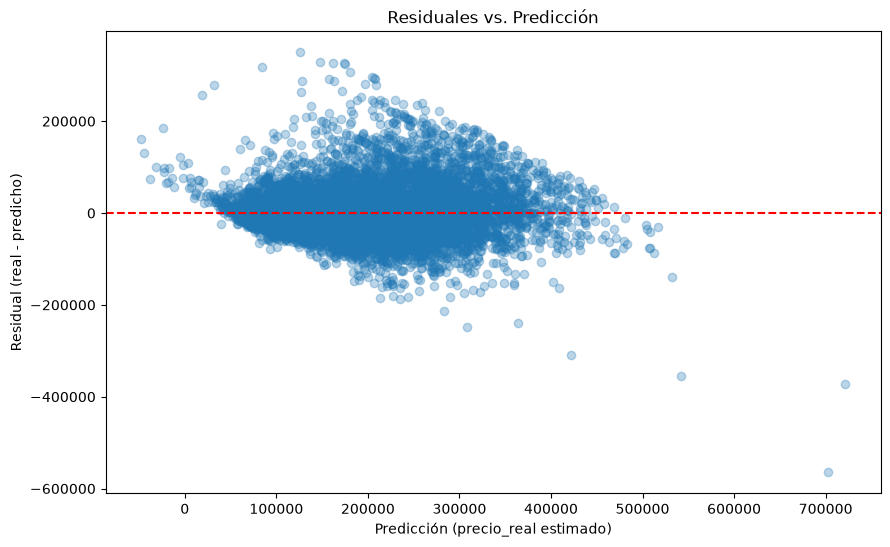

In [81]:
# Graficando los residuales contra la prediccion, para detectar patrones de error (heterocedasticidad, sesgo en algun rango)
plt.figure(figsize=(10, 6))
plt.scatter(evaluando_df['prediccion'], evaluando_df['residual'], alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicción (precio_real estimado)')
plt.ylabel('Residual (real - predicho)')
plt.title('Residuales vs. Predicción')
plt.show()

## Conclusión de la Fase 3: diagnóstico del error

Usando `cross_val_predict` con el modelo Ridge+Polynomial (degree=3, alpha=200) sobre el
train set de la Ronda 2, se construyó `evaluando_df` con el residual y el error absoluto
de cada predicción fuera de fold, y se segmentó por `ocean_proximity` y por rango de precio.

**1. El error relativo es mayor en zonas baratas, no en zonas caras.**
INLAND tiene el error absoluto más bajo en dólares (29,144) pero el error relativo más
alto como % de su propio precio (23.66%), porque es la zona más barata de las cuatro
(~123k de precio promedio). `<1H OCEAN`, NEAR BAY y NEAR OCEAN, con precios promedio
similares (~220k-226k), tienen error relativo menor (17-20%) a pesar de un error en
dólares más alto. El error en dólares por sí solo era engañoso sin normalizar por precio.

**2. El rango de precio "Muy Alto" (243,200-500,000) tiene casi el doble de error que
los otros tres rangos, y no es por tamaño de muestra.**
Los cuatro rangos de precio (creados con `pd.cut` sobre los cuartiles de `precio_real`)
tienen un tamaño casi idéntico (~2,960-2,970 filas cada uno). La causa más probable es
que el dataset describe grupos de manzanas (block groups) del censo de 1990, no viviendas
individuales — no captura calidad de construcción, lote, vista, ni otros factores que
determinan el precio en el segmento alto.

**3. El modelo sobre-predice sistemáticamente en el extremo alto y produce predicciones
negativas en el extremo bajo.**
El gráfico de residuales contra predicción muestra una nube que se abre (heterocedasticidad)
y se inclina hacia residuales negativos en predicciones por encima de ~400k-500k — ya no
existen precios reales por encima de 500,000 (el tope de 500,001 se filtró en la Ronda 1),
así que cualquier predicción más alta solo puede fallar hacia abajo. Además, el valor mínimo
de `prediccion` fue -48,004.86 — un precio negativo, imposible en la realidad. Esto, sumado
a que degree=3 quedó al borde de la grilla en la Fase 2, sugiere que el polinomio de grado 3
puede estar generando comportamiento inestable en los extremos del rango de precios.

**Hipótesis para la Fase 4:** mejor tratamiento de la geografía (más allá de `ocean_proximity`
y lat/long crudos), y revisar si el grado del polinomio es la causa de la inestabilidad en
los extremos o si hace falta otro enfoque para ese segmento.

---
---

## Hipótesis 1 (Fase 4): features de dominio

**Qué se va a hacer:** a partir de la conclusión de Fase 3 (el error relativo es peor en zonas baratas que en caras), se van a crear 3 columnas nuevas a partir de las totales del grupo censal — `rooms_per_household`, `bedrooms_ratio` y `population_per_household` — porque las columnas actuales (`total_rooms`, `total_bedrooms`, etc.) describen el grupo completo, no una vivienda individual. Se agregarán al `ColumnTransformer` y se probará con CV si mejoran el resultado base (30.26%).

In [82]:
# Haciendo una copia explicita antes de modificar X_train_set, para no mutar por accidente el DataFrame original
X_train_set = X_train_set.copy()

In [83]:
# Obteniendo rooms_per_household porque las columnas que tengo son totales del grupo de manzanas no de una casa
X_train_set["rooms_per_household"] = X_train_set["total_rooms"] / X_train_set["households"]

In [84]:
# Obteniendo bedrooms_ratio: que proporcion de los cuartos totales son dormitorios, por grupo censal
X_train_set["bedrooms_ratio"] = X_train_set["total_bedrooms"] / X_train_set["total_rooms"]

In [85]:
# Obteniendo population_per_household: personas promedio por hogar, por grupo censal
X_train_set["population_per_household"] = X_train_set["population"] / X_train_set["households"]

In [86]:
# Viendo las primeras filas para confirmar que las 3 columnas nuevas se agregaron correctamente
X_train_set.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_ratio,population_per_household
0,-118.09,33.91,14.0,2369.0,604.0,1546.0,464.0,3.7969,<1H OCEAN,5.105603,0.254960,3.331897
1,-118.06,34.10,38.0,2438.0,442.0,1308.0,461.0,3.6995,<1H OCEAN,5.288503,0.181296,2.837310
2,-118.50,34.02,24.0,2924.0,1013.0,1492.0,943.0,2.7750,<1H OCEAN,3.100742,0.346443,1.582185
3,-122.18,37.71,45.0,726.0,147.0,519.0,135.0,3.3750,NEAR BAY,5.377778,0.202479,3.844444
4,-118.38,34.09,24.0,8264.0,2437.0,3148.0,2274.0,3.5659,<1H OCEAN,3.634125,0.294894,1.384345


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'rooms_per_household'}>],
       [<Axes: title={'center': 'bedrooms_ratio'}>,
        <Axes: title={'center': 'population_per_household'}>, <Axes: >]],
      dtype=object)

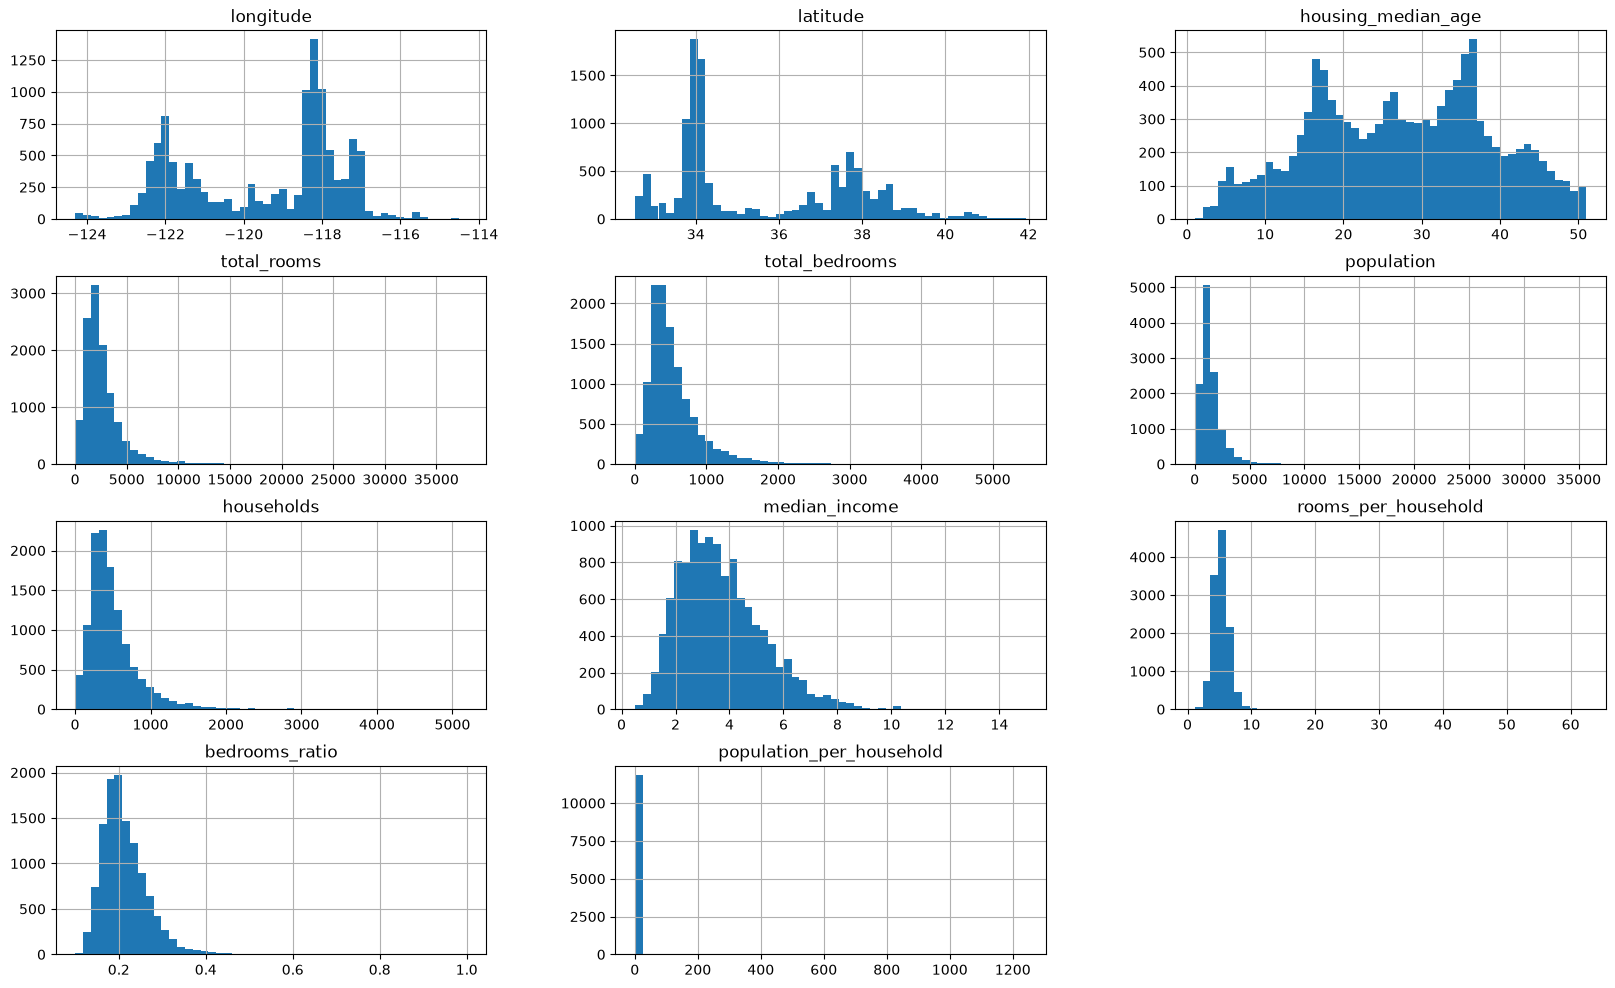

In [87]:
# Graficando histogramas de todas las columnas para revisar la distribucion de las features nuevas
X_train_set.hist(bins=50, figsize=(20, 12))

In [88]:
# Ordenando X_train_set por population_per_household de mayor a menor
X_train_set.sort_values(by="population_per_household", ascending=False)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_ratio,population_per_household
11268,-121.98,38.32,45.0,19.0,5.0,7460.0,6.0,10.2264,INLAND,3.166667,0.263158,1243.333333
5414,-118.59,34.47,5.0,538.0,98.0,8733.0,105.0,4.2391,INLAND,5.123810,0.182156,83.171429
9526,-119.09,34.22,8.0,40.0,10.0,309.0,16.0,4.0208,NEAR OCEAN,2.500000,0.250000,19.312500
10132,-121.04,37.67,16.0,19.0,19.0,166.0,9.0,0.5360,INLAND,2.111111,1.000000,18.444444
7389,-120.97,38.42,16.0,1748.0,322.0,4930.0,287.0,4.3029,INLAND,6.090592,0.184211,17.177700
...,...,...,...,...,...,...,...,...,...,...,...,...
9168,-118.25,34.05,8.0,3105.0,1256.0,1086.0,997.0,0.8131,<1H OCEAN,3.114343,0.404509,1.089268
2131,-118.31,34.06,36.0,369.0,147.0,145.0,136.0,0.8804,<1H OCEAN,2.713235,0.398374,1.066176
3013,-121.00,37.65,17.0,484.0,202.0,198.0,204.0,0.6825,INLAND,2.372549,0.417355,0.970588
4275,-118.44,34.04,16.0,18.0,6.0,3.0,4.0,0.5360,<1H OCEAN,4.500000,0.333333,0.750000


In [89]:
# Contando cuantas filas tienen un valor de population_per_household imposible de sostener (mas de 10 personas por hogar en promedio)
(X_train_set['population_per_household'] > 10).sum()

np.int64(16)

### Despues de hacer este primer diagnostico y verificar que hay outliers en la columna nueva population_per_household, probamos con CV a ver su comportamiento

In [90]:
# Nombres de columnas para cada grupo, usados por el ColumnTransformer
columnas_sesgadas = ["total_rooms", "total_bedrooms", "population", "households", "median_income", "rooms_per_household", "bedrooms_ratio", "population_per_household"]
columnas_no_sesgadas = ['longitude', 'latitude', 'housing_median_age']
columna_categorica = ["ocean_proximity"]

In [91]:
# Reconstruyendo el ColumnTransformer con las columnas_sesgadas actualizadas
column_transformer = ColumnTransformer([
    ("log", pipeline_log, columnas_sesgadas),
    ("simple", pipeline_simple, columnas_no_sesgadas),
    ("cat", pipeline_cat, columna_categorica)
])

In [92]:
# Armando el pipeline de Hipotesis 1 con el mismo degree/alpha ganador de la Fase 2, para aislar el efecto de las features nuevas
pipeline_rid_poly_hipotesis1 = Pipeline([
    ('transform', column_transformer),
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('ridge', Ridge(alpha=200))
])

In [93]:
# Evaluando el pipeline de Hipotesis 1 con 10-fold CV
evaluando_poly_rid = cross_val_score(pipeline_rid_poly_hipotesis1, X_train_set, y_train_set, cv=10, scoring="neg_root_mean_squared_error")

In [94]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluando_dolares_poly_rid = -evaluando_poly_rid
print(evaluando_dolares_poly_rid)

[ 50891.68483221  48472.14680452  52903.58285882  51676.8786808
  51369.34242873  57871.24399205  48976.80954529  49861.61745529
  53956.82786148 145309.02603613]


In [95]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_poly_rid = evaluando_dolares_poly_rid.mean()
rmse_desviacion_poly_rid = evaluando_dolares_poly_rid.std()
print(rmse_promedio_poly_rid)
print(rmse_desviacion_poly_rid)

61128.91604953147
28178.37647588236


In [96]:
# Media y mediana del precio real
precio_promedio_poly_rid = y_train_set.mean()
precio_mediana_poly_rid  = y_train_set.median()
print(precio_promedio_poly_rid)
print(precio_mediana_poly_rid)

189469.47156937074
170500.0


In [97]:
# RMSE como porcentaje de la mediana del precio
porcentaje_poly_rid = rmse_promedio_poly_rid / precio_mediana_poly_rid * 100
print(porcentaje_poly_rid)

35.85273668594221


In [98]:
# Viendo la forma de X_train_set antes de filtrar el outlier de population_per_household
X_train_set.shape

(11871, 12)

In [99]:
# Filtrando outliers de la columna population_per_household
def outliers_population_per_household(X, y):
    filas_validas = X['population_per_household'] <= 10
    X_filtrado = X[filas_validas]
    y_filtrado = y[filas_validas]
    return X_filtrado, y_filtrado
X_train_set, y_train_set = outliers_population_per_household(X_train_set, y_train_set)

In [100]:
# Viendo la forma de X_train_set despues del filtro, para confirmar cuantas filas se eliminaron
X_train_set.shape

(11855, 12)

### Probando nuevamente con CV despues de investigar los outliers que habia de personas por hogar, una cantidad imposible de sostener

In [101]:
# Rearmando el mismo pipeline de Hipotesis 1, ahora sobre los datos ya filtrados
pipeline_rid_poly_hipotesis1_filtrado = Pipeline([
    ('transform', column_transformer),
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('ridge', Ridge(alpha=200))
])

In [102]:
# Evaluando el pipeline filtrado con 10-fold CV
evaluando_poly_rid_filtrado = cross_val_score(pipeline_rid_poly_hipotesis1_filtrado, X_train_set, y_train_set, cv=10, scoring='neg_root_mean_squared_error')

In [103]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluando_dolares_poly_rid_filtrado = -evaluando_poly_rid_filtrado
print(evaluando_dolares_poly_rid_filtrado)

[50746.78782548 47986.88000666 53164.5162616  50252.14026013
 50604.05021199 57987.58936709 48776.99611715 49986.22273422
 51467.89935123 50917.9430899 ]


In [104]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_poly_rid_filtrado = evaluando_dolares_poly_rid_filtrado.mean()
rmse_desviacion_poly_rid_filtrado = evaluando_dolares_poly_rid_filtrado.std()
print(rmse_promedio_poly_rid_filtrado)
print(rmse_desviacion_poly_rid_filtrado)

51189.102522544905
2630.744587399592


In [105]:
# Media y mediana del precio real (cambian levemente porque se quitaron 16 filas)
precio_promedio_poly_rid_filtrado = y_train_set.mean()
precio_mediana_poly_rid_filtrado = y_train_set.median()
print(precio_promedio_poly_rid_filtrado)
print(precio_mediana_poly_rid_filtrado)

189565.63450021087
170700.0


In [106]:
# RMSE como porcentaje de la mediana del precio
porcentaje_poly_rid_filtrado = rmse_promedio_poly_rid_filtrado / precio_mediana_poly_rid_filtrado * 100
print(porcentaje_poly_rid_filtrado)

29.987757775363157


## Hipótesis 1 (Fase 4): features de dominio — RESULTADO: positivo

**Qué se probó:** se crearon 3 columnas nuevas a partir de las totales del grupo de
manzanas — `rooms_per_household` (total_rooms/households), `bedrooms_ratio`
(total_bedrooms/total_rooms) y `population_per_household` (population/households) —
y se agregaron a `columnas_sesgadas` del `ColumnTransformer`, reconstruido para
reflejar el cambio.

**Problema encontrado en el camino:** la primera corrida de CV dio 35.85%, peor que
el 30.26% base — pero 9 de los 10 folds estaban en línea con lo esperado (48k-58k de
RMSE) y uno solo se disparó a 145,309. Se rastreó a 16 filas (de 11,871) con
`population_per_household` > 10, incluyendo una fila con 1,243 "personas por hogar"
— un error de captura de datos, no una distribución natural. Al no reemplazarse la
columna original por el log (la función `aplicar_log` conserva ambas), ese valor
crudo llegaba intacto a `PolynomialFeatures(degree=3)`, generando valores extremos
en cualquier fold donde cayera esa fila.

**Fix:** se filtraron esas 16 filas (`population_per_household <= 10`) de
`X_train_set`/`y_train_set` antes de repetir la CV.

| Versión | CV (% mediana) | Desviación estándar entre folds |
|---|---|---|
| Modelo ganador Fase 2 (sin features nuevas) | 30.26% | — |
| Features nuevas, sin filtrar | 35.85% | 28,178 |
| Features nuevas, filtrado | **29.99%** | **2,631** |

**Conclusión:** las features de dominio sí aportan una mejora real (29.99% vs.
30.26%), pero solo se pudo comprobar después de limpiar el outlier — sin ese paso,
la hipótesis se habría descartado por error, no por ser mala idea. Se mantiene el
filtro de `population_per_household` para las siguientes hipótesis de la Fase 4.

---
---

## Hipótesis 2 (Fase 4): mejor tratamiento de geografía

**Qué se va a hacer:** en vez de usar `latitude`/`longitude` crudas, se va a crear una sola columna `distancia_ciudad` — la distancia mínima de cada casa a San Francisco, Los Ángeles o San Diego — para capturar mejor el efecto de cercanía a centros urbanos sin meter 3 columnas correlacionadas (multicolinealidad). Se probará con CV sobre el resultado ya mejorado de Hipótesis 1 (29.99%).

In [107]:
# Creando columnas de ciudades con su latitud y longuitud
X_train_set["distancia_sf"] = np.sqrt(
    (X_train_set["latitude"] - 37.7749)**2 + (X_train_set["longitude"] - (-122.4194))**2
)

In [108]:
# Calculando la distancia euclidiana de cada fila a Los Angeles
X_train_set["distancia_la"] = np.sqrt(
    (X_train_set["latitude"] - 34.0522)**2 + (X_train_set["longitude"] - (-118.2437))**2
)

In [109]:
# Calculando la distancia euclidiana de cada fila a San Diego
X_train_set["distancia_sd"] = np.sqrt(
    (X_train_set["latitude"] - 32.7157)**2 + (X_train_set["longitude"] - (-117.1611))**2
)

In [110]:
# Obteniendo el valor minimo de las 3 columna creadas fila por fila
X_train_set["distancia_ciudad"] = X_train_set[["distancia_sf", "distancia_la", "distancia_sd"]].min(axis=1)

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>,
        <Axes: title={'center': 'total_rooms'}>],
       [<Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>,
        <Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>],
       [<Axes: title={'center': 'rooms_per_household'}>,
        <Axes: title={'center': 'bedrooms_ratio'}>,
        <Axes: title={'center': 'population_per_household'}>,
        <Axes: title={'center': 'distancia_sf'}>],
       [<Axes: title={'center': 'distancia_la'}>,
        <Axes: title={'center': 'distancia_sd'}>,
        <Axes: title={'center': 'distancia_ciudad'}>, <Axes: >]],
      dtype=object)

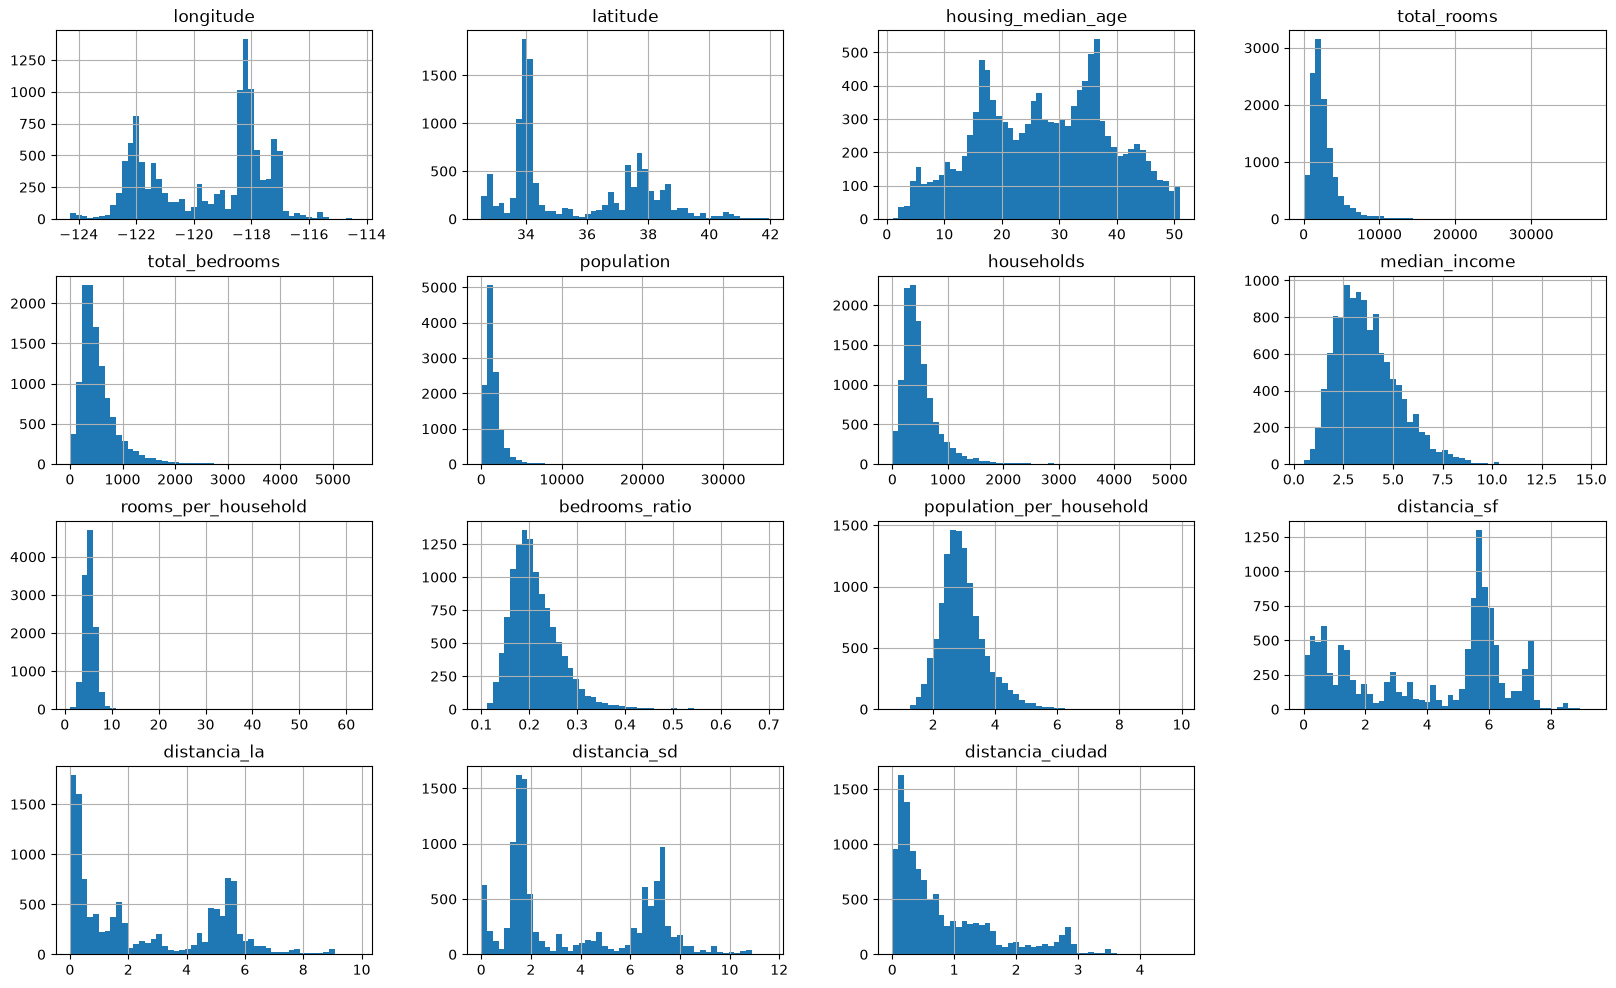

In [111]:
# Graficando histogramas para revisar la distribucion de distancia_ciudad junto a las demas columnas
X_train_set.hist(bins=50, figsize=(20, 12))

In [112]:
# Eliminando columnas que se usaron para sacar la distancia ciudad y mantener el df limpio
X_train_set = X_train_set.drop(columns=["distancia_sf", "distancia_la", "distancia_sd"])

In [113]:
# Nombres de columnas para cada grupo, usados por el ColumnTransformer
columnas_sesgadas = ["total_rooms", "total_bedrooms", "population", "households", "median_income", "rooms_per_household", "bedrooms_ratio", "population_per_household", "distancia_ciudad"]
columnas_no_sesgadas = ['longitude', 'latitude', 'housing_median_age']
columna_categorica = ["ocean_proximity"]

In [114]:
# Reconstruyendo el ColumnTransformer con distancia_ciudad agregada a columnas_sesgadas
column_transformer = ColumnTransformer([
    ("log", pipeline_log, columnas_sesgadas),
    ("simple", pipeline_simple, columnas_no_sesgadas),
    ("cat", pipeline_cat, columna_categorica)
])

In [115]:
# Armando el pipeline de Hipotesis 2 con el mismo degree/alpha de Hipotesis 1, para aislar el efecto de distancia_ciudad
pipeline_rid_poly_hipotesis2 = Pipeline([
    ('transform', column_transformer),
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('ridge', Ridge(alpha=200))
])

In [116]:
# Evaluando el pipeline de Hipotesis 2 con 10-fold CV
evaluacion_rid_poly_2 = cross_val_score(pipeline_rid_poly_hipotesis2, X_train_set, y_train_set, cv=10, scoring='neg_root_mean_squared_error')

In [117]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluando_dolares_rid_poly_2 = -evaluacion_rid_poly_2
print(evaluando_dolares_rid_poly_2)

[49212.56453896 46171.37830701 50938.24437718 46765.24904818
 47831.95600469 54784.03107765 47244.5888085  49041.98150738
 49088.97989999 47828.45563621]


In [118]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_rid_poly_2 = evaluando_dolares_rid_poly_2.mean()
rmse_desviacion_rid_poly_2 = evaluando_dolares_rid_poly_2.std()
print(rmse_promedio_rid_poly_2)
print(rmse_desviacion_rid_poly_2)

48890.742920575496
2365.604006441475


In [119]:
# Media y mediana del precio real
precio_promedio_rid_poly_2 = y_train_set.mean()
precio_mediana_rid_poly_2 = y_train_set.median()
print(precio_promedio_rid_poly_2)
print(precio_mediana_rid_poly_2)

189565.63450021087
170700.0


In [120]:
# RMSE como porcentaje de la mediana del precio
porcentaje_rid_poly_2 = rmse_promedio_rid_poly_2 / precio_mediana_rid_poly_2 * 100
print(porcentaje_rid_poly_2)

28.641325671104568


## Hipótesis 2 (Fase 4): mejor tratamiento de geografía — RESULTADO: positivo

**Qué se probó:** en vez de dejar que el modelo intente inferir cercanía a zonas de
alta demanda solo con `longitude`/`latitude` crudos, se calculó la distancia euclidiana
de cada fila a tres centros económicos de California — San Francisco (37.7749,
-122.4194), Los Ángeles (34.0522, -118.2437) y San Diego (32.7157, -117.1611) — y se
tomó el mínimo de las tres por fila como una sola columna, `distancia_ciudad`, para
evitar redundancia entre columnas muy correlacionadas. Las 3 columnas intermedias
(`distancia_sf`, `distancia_la`, `distancia_sd`) se descartaron después de calcular
el mínimo. Por su distribución (cola larga a la derecha), `distancia_ciudad` se
agregó a `columnas_sesgadas`, y se reconstruyó el `column_transformer`.

| Versión | CV (% mediana) | Desviación estándar entre folds |
|---|---|---|
| Fase 2 (modelo base) | 30.26% | — |
| Hipótesis 1 (features de dominio, filtrado) | 29.99% | 2,631 |
| Hipótesis 2 (+ distancia a ciudad) | **28.64%** | 2,366 |

**Conclusión:** la distancia al centro económico más cercano aporta una mejora real
y consistente (29.99% → 28.64%), sin folds inestables. Se mantiene junto con las
features de la Hipótesis 1 para la siguiente prueba.

---
---

## Hipótesis 3 (Fase 4): grado del polinomio y ajuste de alpha

**Qué se va a hacer:** con las features nuevas de Hipótesis 1 y 2 ya incorporadas, se va a revisar si el grado del polinomio (`degree`) sigue siendo el correcto ahora que hay más columnas, comparando degree=1, 2 y 3 con CV. Luego, con el grado elegido, se usará `GridSearchCV` para encontrar el mejor `alpha` de Ridge.

In [121]:
# Aplicando el ColumnTransformer actualizado para ver cuantas columnas produce ahora, con todas las features acumuladas
resultado_transformado = column_transformer.fit_transform(X_train_set)

In [122]:
# Viendo cuantas columnas produce PolynomialFeatures para cada grado, ahora con mas columnas base que en la Fase 2
for grado in [1, 2, 3]:
    poly_test = PolynomialFeatures(degree=grado, include_bias=False)
    resultado_poly = poly_test.fit_transform(resultado_transformado)
    print(f"Grado {grado}: {resultado_poly.shape[1]} columnas")

Grado 1: 16 columnas
Grado 2: 152 columnas
Grado 3: 968 columnas


In [123]:
# Armando el pipeline de Hipotesis 3 con degree=2 (en vez de 3), para comparar contra el resultado de Hipotesis 2
pipeline_rid_poly_hipotesis3 = Pipeline([
    ('transform', column_transformer),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=200))
])

In [124]:
# Evaluando el pipeline con degree=2 mediante 10-fold CV
evaluacion_rid_poly_3 = cross_val_score(pipeline_rid_poly_hipotesis3, X_train_set, y_train_set, cv=10, scoring="neg_root_mean_squared_error")

In [125]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluacion_dolares_rid_poly_3 = -evaluacion_rid_poly_3
print(evaluacion_dolares_rid_poly_3)

[49830.61376581 47645.3527462  52088.45501803 51353.55868646
 49796.69846856 55617.46623835 50125.44246121 51286.22036311
 50849.5660829  50155.08523732]


In [126]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_rid_poly_3 = evaluacion_dolares_rid_poly_3.mean()
rmse_desviacion_rid_poly_3 = evaluacion_dolares_rid_poly_3.std()
print(rmse_promedio_rid_poly_3)
print(rmse_desviacion_rid_poly_3)

50874.84590679572
1952.5992498478615


In [127]:
# Media y mediana del precio real
precio_promedio_rid_poly_3 = y_train_set.mean()
precio_mediana_rid_poly_3 = y_train_set.median()
print(precio_promedio_rid_poly_3)
print(precio_mediana_rid_poly_3)

189565.63450021087
170700.0


In [128]:
# RMSE como porcentaje de la mediana del precio
porcentaje_rid_poly_3 = rmse_promedio_rid_poly_3 / precio_mediana_rid_poly_3 * 100
print(porcentaje_rid_poly_3)

29.80365899636539


## Hipótesis 3 (Fase 4): grado del polinomio — RESULTADO: se mantiene degree=2

**Qué se investigó:** con las features de las Hipótesis 1 y 2 ya acumuladas (16
columnas base tras el `ColumnTransformer`), se repitió la verificación de
columnas-vs-filas de la Fase 2 para ver si `degree=3` seguía siendo razonable.

| Grado | Columnas generadas | Filas por columna (11,855 filas) |
|---|---|---|
| 2 | 152 | ~78 |
| 3 | 968 | ~12 |

La proporción de degree=3 empeoró bastante respecto a la Fase 2 (~26 filas/columna
entonces), por tener más columnas base ahora.

**Comparación por CV** (mismo `Ridge(alpha=200)`, mismas features, solo cambia el grado):

| Versión | CV (% mediana) | Desviación estándar |
|---|---|---|
| Hipótesis 2 (degree=3) | 28.64% | 2,366 |
| Hipótesis 3 (degree=2) | 29.80% | 1,953 |

**Discusión:** degree=3 dio mejor CV que degree=2 — si degree=3 estuviera
sobreajustando a ruido, degree=2 lo habría superado, y no fue el caso. No hay
evidencia de sobreajuste actual. Aun así, se decidió seguir con **degree=2** como
base, por una razón de margen, no de sobreajuste: todavía quedan hipótesis por
probar en esta fase, y cada feature nueva agrega más columnas en degree=3 (ya
cerca de un límite riesgoso), mientras que degree=2 deja espacio cómodo para
seguir iterando sin acercarse a una proporción filas/columnas peligrosa.

**Referencia de meta:** se investigó el RMSE típico de Random Forest sobre este
mismo dataset (~27-29% de la mediana, según benchmarks documentados), confirmando
que un 10% no es una meta realista aquí — ni modelos más potentes que Ridge+Polynomial
bajan mucho de ese rango con estos datos. Meta establecida para esta ronda: ~27.8%,
aceptable si queda justo por encima de 28%.

---
---

### Ajuste fino de alpha (GridSearchCV): buscando el mejor valor en dos rondas

**Qué se va a hacer:** con `degree=2` ya decidido en Hipótesis 3, se va a usar `GridSearchCV` para encontrar el mejor `alpha` de Ridge, probando primero el mismo rango usado en la Fase 2 (`[1, 10, 50, 100, 200, 300, 500]`). Si el ganador queda pegado a alguno de los extremos de la grilla, se va a repetir la búsqueda con un rango ajustado alrededor de ese extremo, para no dejar pasar un óptimo fuera del rango original.


In [129]:
# Grilla de alpha con degree=2 fijo, para encontrar el mejor alpha de Ridge ahora que el grado ya quedo decidido
param_grid = [
    {'poly__degree': [2],
    'ridge__alpha': [1.0,10.0,50.0,100.0,200.0,300.0,500.0]},
]
buscando_mejor_rid_poly = GridSearchCV(pipeline_rid_poly_hipotesis3, param_grid, cv=10, scoring='neg_root_mean_squared_error')

In [130]:
# Ejecutando la busqueda del mejor alpha con 10-fold CV
buscando_mejor_rid_poly.fit(X_train_set, y_train_set)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(alpha=200))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'poly__degree': [2], 'ridge__alpha': [1.0, 10.0, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the 

In [131]:
# Mostrando el mejor alpha encontrado y su score; gano el borde inferior de la grilla, senal de que el optimo real puede ser menor
print(buscando_mejor_rid_poly.best_params_)
print(buscando_mejor_rid_poly.best_score_)

{'poly__degree': 2, 'ridge__alpha': 1.0}
-49966.977838686675


In [132]:
# Convirtiendo el mejor score a dolares (positivo)
score_dolares_rid_poly = -buscando_mejor_rid_poly.best_score_
print(score_dolares_rid_poly)

49966.977838686675


In [133]:
# RMSE del mejor modelo como porcentaje de la mediana del precio
porcentaje_rid_poly_score = score_dolares_rid_poly / precio_mediana_rid_poly_3 * 100
print(porcentaje_rid_poly_score)

29.271808927174387


In [134]:
# Verificando si el alpha=1 es el mejor o es un numero mas pequeno probando otra ves con gridserch
param_grid = [
    {'poly__degree': [2],
    'ridge__alpha': [0.001, 0.01, 0.1, 0.5, 1.0]},
]
buscando_mejor_prueba = GridSearchCV(pipeline_rid_poly_hipotesis3, param_grid, cv=10, scoring='neg_root_mean_squared_error')

In [135]:
# Ejecutando la segunda busqueda, con valores de alpha mas pequenos
buscando_mejor_prueba.fit(X_train_set, y_train_set)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(alpha=200))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'poly__degree': [2], 'ridge__alpha': [0.001, 0.01, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls th

In [136]:
# Mostrando el mejor alpha de la segunda ronda; ya no cae en el borde de la grilla
print(buscando_mejor_prueba.best_params_)
print(buscando_mejor_prueba.best_score_)

{'poly__degree': 2, 'ridge__alpha': 0.01}
-49928.38212846785


In [137]:
# Convirtiendo el mejor score a dolares (positivo)
score_dolares_prueba = -buscando_mejor_prueba.best_score_
print(score_dolares_prueba)

49928.38212846785


In [138]:
# RMSE del mejor modelo como porcentaje de la mediana del precio
porcentaje_rid_poly_prueba = score_dolares_prueba / precio_mediana_rid_poly_3 * 100
print(porcentaje_rid_poly_prueba)

29.249198669284038


## Ajuste fino de alpha (GridSearchCV) — tras Hipótesis 3

**Qué se hizo:** con `degree=2` fijo, se corrió `GridSearchCV` sobre `alpha` en dos
rondas. Primera ronda, mismo rango de la Fase 2 (`[1, 10, 50, 100, 200, 300, 500]`):
ganó `alpha=1.0`, pegado al borde inferior de la grilla — señal de que el óptimo
real podía ser menor. Segunda ronda, con valores más chicos
(`[0.001, 0.01, 0.1, 0.5, 1.0]`): ganó `alpha=0.01`, ya sin quedar en el borde.

| Alpha probado | CV (% mediana) |
|---|---|
| 1.0 (primera ronda) | 29.27% |
| 0.01 (segunda ronda) | 29.25% |

**Conclusión:** la diferencia entre ambos (0.02 puntos) es ruido, no mejora real —
el ajuste de `alpha` llegó a su límite. Que el óptimo esté tan cerca de cero indica
que el conjunto de features (tras filtrar el outlier y mantener degree=2) ya está
limpio y no necesita mucha regularización. Resultado final de esta vía: **29.25%**,
por encima de la meta de ~27.8-28% fijada para esta ronda.

Con las hipótesis "baratas" agotadas, se pasa a la más ambiciosa pendiente:
segmentar el modelo por zona geográfica (costa vs. interior).

---
---

## Hipótesis 4 (Fase 4): segmentación del modelo (interior vs. costa)

**Qué se va a hacer:** en el diagnóstico de Fase 3 se vio que INLAND tenía el peor error relativo de las 4 zonas. En vez de seguir ajustando un solo modelo para todo el dataset, se va a dividir `X_train_set`/`y_train_set` en dos subconjuntos según `ocean_proximity == 'INLAND'`, y se entrenará un modelo Ridge+Polynomial independiente para cada uno (cada uno con su propio `ColumnTransformer` y su propio `GridSearchCV` de alpha), para ver si capturar las dinámicas de precio distintas de cada zona mejora el resultado combinado.

In [139]:
# Creando una mascara booleana para separar las filas de zona interior (INLAND) del resto, y usandola para dividir X e y
es_interior_x = X_train_set['ocean_proximity'] == 'INLAND'

X_interior = X_train_set[es_interior_x]
y_interior = y_train_set[es_interior_x]

In [140]:
# Verificando cuantas filas quedaron en el segmento interior
print(X_interior.shape)
print(y_interior.shape)

(4055, 13)
(4055,)


In [141]:
# Invirtiendo la mascara para obtener el segmento de costa (todo lo que no es INLAND), y dividiendo X e y
es_costa_x = ~es_interior_x
X_costa = X_train_set[es_costa_x]
y_costa = y_train_set[es_costa_x]

In [142]:
# Verificando cuantas filas quedaron en el segmento costa
print(X_costa.shape)
print(y_costa.shape)

(7800, 13)
(7800,)


In [143]:
# Armando un ColumnTransformer independiente para el segmento interior, para que ajuste sus propios parametros de escalado/imputacion sobre esos datos
column_transformer_interior = ColumnTransformer([
    ('log', pipeline_log, columnas_sesgadas),
    ('simple', pipeline_simple, columnas_no_sesgadas),
    ('cat', pipeline_cat, columna_categorica)
])

In [144]:
# Armando el pipeline inicial para interior (degree=2, alpha=0.01 de prueba) antes de buscar el alpha optimo
pipeline_interior = Pipeline([
    ('transformer', column_transformer_interior),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=0.01))
])

In [145]:
# Evaluando el pipeline inicial de interior con 10-fold CV
evaluando_interior = cross_val_score(pipeline_interior, X_interior, y_interior, cv=10, scoring='neg_root_mean_squared_error')

In [146]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluacion_dolares_interior = -evaluando_interior
print(evaluacion_dolares_interior)

[33952.00564566 39992.94585697 40097.45870232 34976.63773586
 37524.15073734 47297.30111731 35683.32770944 34971.00736023
 38411.64483073 36514.23106697]


In [147]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_interior = evaluacion_dolares_interior.mean()
rmse_desviacion_interior = evaluacion_dolares_interior.std()
print(rmse_promedio_interior)
print(rmse_desviacion_interior)

37942.07107628281
3707.4189749359207


In [148]:
# Media y mediana del precio real, solo del segmento interior
precio_promedio_interior = y_interior.mean()
precio_mediana_interior = y_interior.median()
print(precio_promedio_interior)
print(precio_mediana_interior)

123217.92774352651
108300.0


In [149]:
# RMSE como porcentaje de la mediana del precio del segmento interior
porcentaje_interior = rmse_promedio_interior / precio_mediana_interior * 100
print(porcentaje_interior)

35.03422998733408


In [150]:
# Grilla de alpha para buscar el mejor valor especifico del segmento interior
param_grid = [
    {'poly__degree': [2],
    'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 50, 100, 200]}
]

buscando_mejor_interior = GridSearchCV(pipeline_interior, param_grid, cv=10, scoring='neg_root_mean_squared_error')

In [151]:
# Ejecutando la busqueda del mejor alpha para el segmento interior
buscando_mejor_interior.fit(X_interior, y_interior)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...alpha=0.01))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'poly__degree': [2], 'ridge__alpha': [0.001, 0.01, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls th

In [152]:
# Mostrando el mejor alpha encontrado para interior
print(buscando_mejor_interior.best_params_)
print(buscando_mejor_interior.best_score_)

{'poly__degree': 2, 'ridge__alpha': 50}
-37499.379115021395


In [153]:
# Convirtiendo el mejor score de interior a dolares (positivo)
score_dolares_interior = -buscando_mejor_interior.best_score_
print(score_dolares_interior)

37499.379115021395


In [154]:
# RMSE optimo de interior como porcentaje de su propia mediana de precio
porcentaje_interior = score_dolares_interior / precio_mediana_interior * 100
print(porcentaje_interior)

34.62546548016749


In [155]:
# Armando un ColumnTransformer independiente para el segmento costa, con sus propios parametros ajustados sobre esos datos
column_transformer_costa = ColumnTransformer([
    ('log', pipeline_log, columnas_sesgadas),
    ('simple', pipeline_simple, columnas_no_sesgadas),
    ('cat', pipeline_cat, columna_categorica)
])

In [156]:
# Armando el pipeline inicial para costa (degree=2, alpha=0.01 de prueba) antes de buscar el alpha optimo
pipeline_costa = Pipeline([
    ('transformer', column_transformer_costa),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=0.01))
])

In [157]:
# Evaluando el pipeline inicial de costa con 10-fold CV
evaluando_costa = cross_val_score(pipeline_costa, X_costa, y_costa, cv=10, scoring='neg_root_mean_squared_error')

In [158]:
# Convirtiendo el resultado a dolares y viendo el RMSE de cada fold por separado
evaluacion_dolares_costa = -evaluando_costa
print(evaluacion_dolares_costa)

[53348.99171436 50778.20636062 52729.3648078  54911.49593859
 54170.45805294 57067.70450997 53828.09321341 54315.94512646
 52231.51736549 53382.33021641]


In [159]:
# Promedio y desviacion estandar del RMSE entre los 10 folds
rmse_promedio_costa = evaluacion_dolares_costa.mean()
rmse_desviacion_costa = evaluacion_dolares_costa.std()
print(rmse_promedio_costa)
print(rmse_desviacion_costa)

53676.41073060605
1589.9777197312358


In [160]:
# Media y mediana del precio real, solo del segmento costa
precio_promedio_costa = y_costa.mean()
precio_mediana_costa = y_costa.median()
print(precio_promedio_costa)
print(precio_mediana_costa)

224057.9358974359
207050.0


In [161]:
# RMSE como porcentaje de la mediana del precio del segmento costa
porcentaje_costa = rmse_promedio_costa / precio_mediana_costa * 100
print(porcentaje_costa)

25.924371277761914


In [162]:
# Grilla de alpha para buscar el mejor valor especifico del segmento costa
param_grid = [
    {'poly__degree': [2],
    'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 50, 100, 200]}
]

buscando_mejor_costa = GridSearchCV(pipeline_costa, param_grid, cv=10, scoring='neg_root_mean_squared_error')

In [163]:
# Ejecutando la busqueda del mejor alpha para el segmento costa
buscando_mejor_costa.fit(X_costa, y_costa)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...alpha=0.01))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'poly__degree': [2], 'ridge__alpha': [0.001, 0.01, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls th

In [164]:
# Mostrando el mejor alpha encontrado para costa; resulto casi insensible al valor de alpha
print(buscando_mejor_costa.best_params_)
print(buscando_mejor_costa.best_score_)

{'poly__degree': 2, 'ridge__alpha': 0.001}
-53676.31896625496


In [165]:
# Convirtiendo el mejor score de costa a dolares (positivo)
score_dolares_costa = -buscando_mejor_costa.best_score_
print(score_dolares_costa)

53676.31896625496


In [166]:
# RMSE optimo de costa como porcentaje de su propia mediana de precio
porcentaje_costa = score_dolares_costa / precio_mediana_costa * 100
print(porcentaje_costa)

25.92432695786282


In [167]:
# Recuperando la suma de errores al cuadrado (RMSE)
suma_errores_interior = score_dolares_interior**2 * 4055
suma_errores_costa = score_dolares_costa**2 * 7800

In [168]:
# Sumando los dos errores, dividiendo por la cantidad de filas totales y sacar la raiz para obtener el RMSE combinado
rmse_combinado = ((suma_errores_interior + suma_errores_costa) / (4055 + 7800))**0.5
print(rmse_combinado)

48750.82603070331


In [169]:
# RMSE combinado como porcentaje de la mediana del precio, para comparar directamente contra el 29.25% del modelo unico
porcentaje_comparacion = rmse_combinado / precio_mediana_rid_poly_3 * 100
print(porcentaje_comparacion)

28.55935912753563


## Cierre de Hipótesis 4: Segmentación del modelo (interior vs. costa)

**Hipótesis:** El modelo único trata por igual zonas con dinámicas de precio muy distintas (interior vs. costa), lo que podría estar limitando su precisión. Separar el entrenamiento en dos modelos especializados —uno para zonas `INLAND` y otro para el resto (`costa`)— podría capturar mejor esas diferencias.

**Construcción:**
- Se dividió `X_train_set`/`y_train_set` usando una condición booleana sobre `ocean_proximity == 'INLAND'`, obteniendo dos subconjuntos independientes: interior (4,055 filas) y costa (7,800 filas).
- Se construyó un `ColumnTransformer` independiente para cada segmento (misma estructura que el modelo combinado: log, simple, categórica), ya que cada uno debe ajustar sus propios parámetros de escalado/imputación según los datos de su segmento.
- Se armó un pipeline por segmento (`PolynomialFeatures(degree=2)` + `Ridge`), y se corrió `GridSearchCV` sobre una grilla amplia de `alpha` para cada uno por separado.

**Resultados por segmento:**

| Segmento | Filas | RMSE óptimo | % sobre mediana | Alpha ganador |
|---|---|---|---|---|
| Interior | 4,055 | $37,499 | 34.63% | 50 |
| Costa | 7,800 | $53,676 | 25.92% | 0.001 |

- Interior necesitó bastante más regularización (alpha=50) que el modelo combinado, probablemente porque tiene menos filas para la misma cantidad de columnas generadas por `degree=2`, aumentando el riesgo de sobreajuste si no se regulariza más.
- Costa resultó prácticamente insensible al alpha (0.001 y 0.01 dieron el mismo resultado), señal de que ya tiene suficiente data limpia para generalizar bien sin apenas shrinkage.

**Comparación contra el modelo único:**
Para comparar de forma justa contra el baseline (un solo modelo sobre todo el train), se combinaron los dos RMSE mediante la recuperación de la suma de errores al cuadrado de cada segmento (`RMSE² × n_filas`), sumándolas, dividiendo por el total de filas, y sacando la raíz — el método matemáticamente correcto para combinar RMSEs de distintos grupos (no es un simple promedio ponderado).

- **RMSE combinado:** $48,750.83
- **% sobre la mediana general de train:** **28.56%**
- **Baseline (modelo único, degree=2, alpha=0.01):** 29.25%

**Decisión:** La segmentación produjo una mejora de 0.69 puntos porcentuales (29.25% → 28.56%), acercando el modelo al margen de referencia investigado (~27.8%, basado en benchmarks publicados sobre este mismo dataset). Aunque la ganancia es modesta frente al costo de mantener dos `ColumnTransformer`, dos pipelines y dos procesos de tuning en paralelo, se decide conservar la segmentación porque:
1. Es la mejora más significativa encontrada hasta ahora en Fase 4.
2. Acerca el modelo al límite inherente del dataset, dado que no hay información a nivel de vivienda individual disponible.
3. No se identificó una alternativa más simple con ganancia comparable.

Esto implica que, de aquí en adelante, el modelo final estará compuesto por **dos modelos independientes**, cada uno aplicado a su segmento correspondiente de `ocean_proximity`, lo cual deberá replicarse de forma idéntica sobre el test set en Fase 6 (incluyendo la misma división booleana y la aplicación de cada pipeline entrenado a su subconjunto correspondiente).

---
---

### Reconstruyendo los pipelines con los alphas ganadores reales

**Qué se va a hacer:** antes de poder validar el 28.56% con predicciones reales, hay que asegurarse de que los pipelines usados sean los correctos. `pipeline_interior` y `pipeline_costa` (de Hipótesis 4) se quedaron con el alpha de prueba inicial (0.01) y nunca se actualizaron tras el `GridSearchCV` — así que se van a reconstruir como `pipeline_interior_new` (alpha=50) y `pipeline_costa_new` (alpha=0.001), con los alphas que realmente ganaron la búsqueda, y se va a correr `cross_val_predict` en cada segmento para obtener las predicciones reales fuera de muestra.


In [170]:
# Reconstruyendo el pipeline de interior con el alpha ganador real del GridSearchCV (50), ya que pipeline_interior se quedo con el alpha de prueba (0.01)
pipeline_interior_new = Pipeline([
    ('transformer', column_transformer_interior),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=50))
])

In [171]:
# Obteniendo las predicciones reales out-of-sample del segmento interior con el pipeline ya actualizado
evaluando_interior_new = cross_val_predict(pipeline_interior_new, X_interior, y_interior, cv=10)

In [172]:
# Reconstruyendo el pipeline de costa con el alpha ganador real del GridSearchCV (0.001), ya que pipeline_costa se quedo con el alpha de prueba (0.01)
pipeline_costa_new = Pipeline([
    ('transformer', column_transformer_costa),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=0.001))
])

In [173]:
# Obteniendo las predicciones reales out-of-sample del segmento costa con el pipeline ya actualizado
evaluando_costa_new = cross_val_predict(pipeline_costa_new, X_costa, y_costa, cv=10)

In [174]:
# Uniendo las predicciones de ambos segmentos en un solo array
interior_costa_predict = np.concatenate([evaluando_interior_new, evaluando_costa_new])

In [175]:
# Uniendo los valores reales de ambos segmentos en un solo array, en el mismo orden que las predicciones
interior_costa_reales = np.concatenate([y_interior, y_costa])

In [176]:
# Calculando un unico RMSE real sobre el conjunto combinado, en vez de combinar dos RMSE ya resumidos
from sklearn.metrics import root_mean_squared_error

rmse_interior_costa = root_mean_squared_error(interior_costa_reales, interior_costa_predict)

In [177]:
# RMSE real combinado como porcentaje de la mediana del precio, para comparar contra el 28.56% calculado matematicamente
porcentaje_interior_costa = rmse_interior_costa / precio_mediana_rid_poly_3 * 100
print(porcentaje_interior_costa)

28.600522121268956


### Cierre: pipelines reconstruidos y predicciones out-of-sample obtenidas

**Qué se hizo:** se reconstruyeron `pipeline_interior_new` (alpha=50) y `pipeline_costa_new` (alpha=0.001) con los alphas ganadores reales del `GridSearchCV`, en vez de reusar `pipeline_interior`/`pipeline_costa`, que se habían quedado con el alpha de prueba inicial (0.01). Se corrió `cross_val_predict` por separado en cada segmento para obtener las predicciones reales fuera de muestra, y se concatenaron ambos segmentos (predicciones y valores reales) en un solo conjunto de 11,855 filas.

**Resultado:** el RMSE real sobre ese conjunto combinado dio **28.60%** — a solo 0.04 puntos del 28.56% calculado matemáticamente en el cierre de Hipótesis 4, confirmando que ambos pipelines quedaron correctamente actualizados antes de dar por válido el resultado.


## Validación de Hipótesis 4: comprobando el 28.56% con predicciones reales

**Qué se va a hacer:** el 28.56% de Hipótesis 4 se calculó combinando matemáticamente los dos `best_score_` del GridSearchCV (interior y costa) con la fórmula `RMSE² × n`. Antes de aceptarlo como definitivo, se va a reconstruir cada pipeline con el alpha ganador real (revisando que no haya quedado ninguna referencia obsoleta a los alphas de prueba), correr `cross_val_predict` por separado en cada segmento para obtener predicciones reales fuera de muestra, concatenar ambos segmentos en un solo conjunto, y calcular un único RMSE real con `root_mean_squared_error` — para confirmar que el atajo matemático no estaba ocultando algo.


## Validación del resultado de Hipótesis 4: RMSE real con predicciones out-of-sample

**Propósito:** El 28.56% de Hipótesis 4 se obtuvo combinando matemáticamente los dos `best_score_` de los GridSearchCV (interior y costa) mediante `RMSE² × n`. Antes de aceptar esa cifra como definitiva, se validó usando predicciones reales fuera de muestra (`cross_val_predict`), para confirmar que el atajo matemático no estaba ocultando algo.

**Verificación adicional:** se revisó que `columnas_sesgadas` (usada por `column_transformer_interior` y `column_transformer_costa`) estuviera actualizada con las features más recientes (`rooms_per_household`, `bedrooms_ratio`, `population_per_household`, `distancia_ciudad`) — confirmado correcto, sin referencias obsoletas.

**Construcción:**
- Se reconstruyeron los pipelines con los alphas ganadores del `GridSearchCV` (`pipeline_interior_new` con alpha=50, `pipeline_costa_new` con alpha=0.001), ya que los pipelines originales (`pipeline_interior`, `pipeline_costa`) se habían quedado con los alphas de prueba iniciales (0.01) y nunca se actualizaron tras el tuning.
- Se corrió `cross_val_predict` (cv=10) por separado para cada segmento, obteniendo las predicciones out-of-sample reales de las 4,055 filas de interior y las 7,800 de costa.
- Se concatenaron ambos arrays de predicciones y ambos arrays de valores reales en un solo conjunto de 11,855 filas (`interior_costa_predict`, `interior_costa_reales`).
- Se calculó un único RMSE directo sobre ese conjunto combinado con `root_mean_squared_error`, en vez de combinar dos RMSE ya resumidos.

**Resultado:**

| Método | RMSE (% sobre mediana) |
|---|---|
| Combinación matemática (`RMSE² × n`, Hipótesis 4) | 28.56% |
| Validación real (`cross_val_predict` concatenado) | **28.60%** |

**Conclusión:** La diferencia entre ambos métodos es de solo 0.04 puntos porcentuales — prácticamente despreciable. Esto confirma que la combinación matemática usada en el cierre de Hipótesis 4 no era un atajo riesgoso, sino una aproximación confiable al resultado real. Se da por **validado** el 28.56%/28.60% como el desempeño actual del modelo segmentado (interior + costa), y se mantiene la decisión de conservar la segmentación tomada en Hipótesis 4.

---
---

### Construyendo y analizando `residuales_df_final`: residuales del modelo segmentado (punto 3)

**Qué se va a hacer:** ya validado el 28.56%/28.60% de Hipótesis 4, se va a construir `residuales_df_final` — uniendo las predicciones y valores reales ya concatenados (`interior_costa_predict`, `interior_costa_reales`) con las columnas de contexto de ambos segmentos (`median_income`, `latitude`, `longitude`, `ocean_proximity`, `distancia_ciudad`) — y luego analizarlo desde cuatro ángulos: zona (`ocean_proximity`), rango de precio, ingreso (`median_income`) y ubicación geográfica (lat/long), para detectar si queda algún patrón de error que justifique una Hipótesis 5, en vez de decidir a ciegas si seguir ajustando el modelo.


In [178]:
# Uniendo las columnas de contexto (ingreso, lat/long, zona, distancia_ciudad) de ambos segmentos en el mismo orden que las predicciones, para poder analizar los residuales por esos angulos
concat_interior_costa = pd.concat([X_interior[["median_income", "latitude", "longitude", "ocean_proximity", "distancia_ciudad"]], 
                                X_costa[["median_income", "latitude", "longitude", "ocean_proximity", "distancia_ciudad"]]], ignore_index=True) # El ignore_index=True asegura que los índices se restablezcan correctamente después de la concatenación, es lo mismo que usar reset_index

In [179]:
# Armando un DataFrame con el precio real, la prediccion, el residual y el error absoluto del modelo segmentado combinado
evaluando_residual = pd.DataFrame({
    'precio_real': interior_costa_reales,
    'prediccion': interior_costa_predict,
    'residual': interior_costa_reales - interior_costa_predict,
    'error_absoluto': np.abs(interior_costa_reales - interior_costa_predict),
})

In [180]:
# Juntando las columnas de error con las columnas de contexto en un solo DataFrame, por posicion de columna (axis=1)
residuales_df_final = pd.concat([evaluando_residual, concat_interior_costa], axis=1)

In [181]:
# Verificando que todas las columnas esperadas esten presentes antes de analizar
residuales_df_final.columns.to_list()

['precio_real',
 'prediccion',
 'residual',
 'error_absoluto',
 'median_income',
 'latitude',
 'longitude',
 'ocean_proximity',
 'distancia_ciudad']

In [182]:
# Precio promedio real por zona, para poder calcular el error relativo mas adelante
precio_promedio_categoria = residuales_df_final.groupby("ocean_proximity")["precio_real"].mean()
print(precio_promedio_categoria)

ocean_proximity
<1H OCEAN     223790.146396
INLAND        123217.927744
NEAR BAY      222541.444115
NEAR OCEAN    226083.915127
Name: precio_real, dtype: float64


In [183]:
# Promedio de error absoluto por zona, del modelo ya segmentado
promedio_error_abs = residuales_df_final.groupby("ocean_proximity")["error_absoluto"].mean()
print(promedio_error_abs)

ocean_proximity
<1H OCEAN     37781.794217
INLAND        25134.019751
NEAR BAY      38864.328309
NEAR OCEAN    42671.594290
Name: error_absoluto, dtype: float64


In [184]:
# Convirtiendo el error absoluto a error relativo (% del precio promedio de cada zona), para comparar contra los resultados de la Fase 3
porcentaje_error_relativo = promedio_error_abs / precio_promedio_categoria * 100
print(porcentaje_error_relativo)

ocean_proximity
<1H OCEAN     16.882689
INLAND        20.398022
NEAR BAY      17.463861
NEAR OCEAN    18.874228
dtype: float64


In [185]:
# Viendo un resumen estadistico general del modelo segmentado
residuales_df_final.describe()

,precio_real,prediccion,residual,error_absoluto,median_income,latitude,longitude,distancia_ciudad
count,11855.0000,11855.000000,11855.000000,11855.000000,11855.000000,11855.000000,11855.000000,11855.000000
mean,189565.6345,189562.289965,3.344535,34150.559668,3.693748,35.602569,-119.490634,0.825953
std,96162.7361,83728.401766,48823.150370,34890.412898,1.572618,2.154273,1.983463,0.824849
min,14999.0000,-33835.374592,-398660.231353,3.751430,0.499900,32.540000,-124.300000,0.004438
25%,115000.0000,122481.286681,-26873.116737,11142.038683,2.539500,33.920000,-121.570000,0.213536
50%,170700.0000,179783.029773,-5041.195484,24350.299450,3.475000,34.240000,-118.460000,0.499053
75%,243300.0000,247469.308742,20641.275012,45409.773654,4.604600,37.680000,-117.970000,1.213850
max,500000.0000,690616.942660,377815.670271,398660.231353,15.000100,41.950000,-114.310000,4.646915


In [186]:
# Creando los mismos 4 rangos de precio de la Fase 3 (ajustados a la mediana actual) para comparar el error por rango
residuales_df_final["rango_precio"] = pd.cut(residuales_df_final["precio_real"], bins=[14999, 115000, 170700, 243300, 500000], labels=["Bajo", "Medio", "Alto", "Muy Alto"])

In [187]:
# Promedio de error absoluto por rango de precio, del modelo ya segmentado
error_abs_promedio = residuales_df_final.groupby("rango_precio")["error_absoluto"].mean()
print(error_abs_promedio)

rango_precio
Bajo        23332.748131
Medio       28360.151436
Alto        32305.294414
Muy Alto    52595.718985
Name: error_absoluto, dtype: float64


In [188]:
# Verificando que los 4 rangos tengan un tamano de muestra similar
residuales_df_final['rango_precio'].value_counts()

rango_precio
Bajo        2964
Medio       2964
Muy Alto    2963
Alto        2961
Name: count, dtype: int64

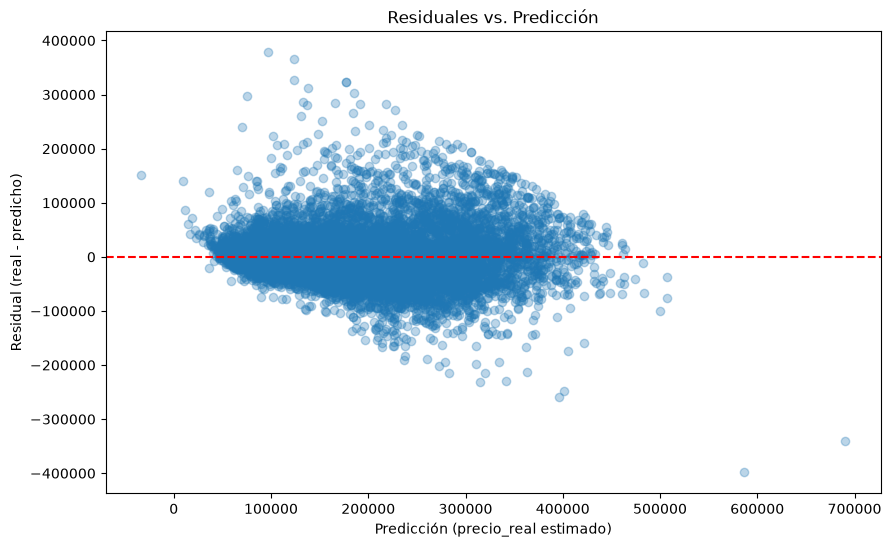

In [189]:
# Graficando los residuales del modelo segmentado contra la prediccion, para comparar visualmente contra el grafico de la Fase 3
plt.figure(figsize=(10, 6))
plt.scatter(residuales_df_final['prediccion'], residuales_df_final['residual'], alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicción (precio_real estimado)')
plt.ylabel('Residual (real - predicho)')
plt.title('Residuales vs. Predicción')
plt.show()

In [190]:
# Creando 4 rangos de median_income (cuartiles) para ver si el error tambien varia segun el nivel de ingreso
residuales_df_final["rango_income"] = pd.cut(residuales_df_final["median_income"], bins=[0.499900, 2.539500, 3.475000, 4.604600, 15.000100], labels=["Bajo", "Medio", "Alto", "Muy Alto"])

In [191]:
# Promedio de error absoluto por rango de ingreso
error_abs_promedio_income = residuales_df_final.groupby("rango_income")["error_absoluto"].mean()
print(error_abs_promedio_income)

rango_income
Bajo        28904.472059
Medio       31273.084659
Alto        35395.872263
Muy Alto    41035.315013
Name: error_absoluto, dtype: float64


In [192]:
# Verificando si median_income y precio_real suben juntos, para confirmar si el patron de error
# por rango_income es informacion nueva o el mismo patron de precio visto desde otro angulo 
matriz_correlacion = residuales_df_final[['precio_real', 'median_income']].corr()
print(matriz_correlacion)

               precio_real  median_income
precio_real       1.000000       0.659817
median_income     0.659817       1.000000


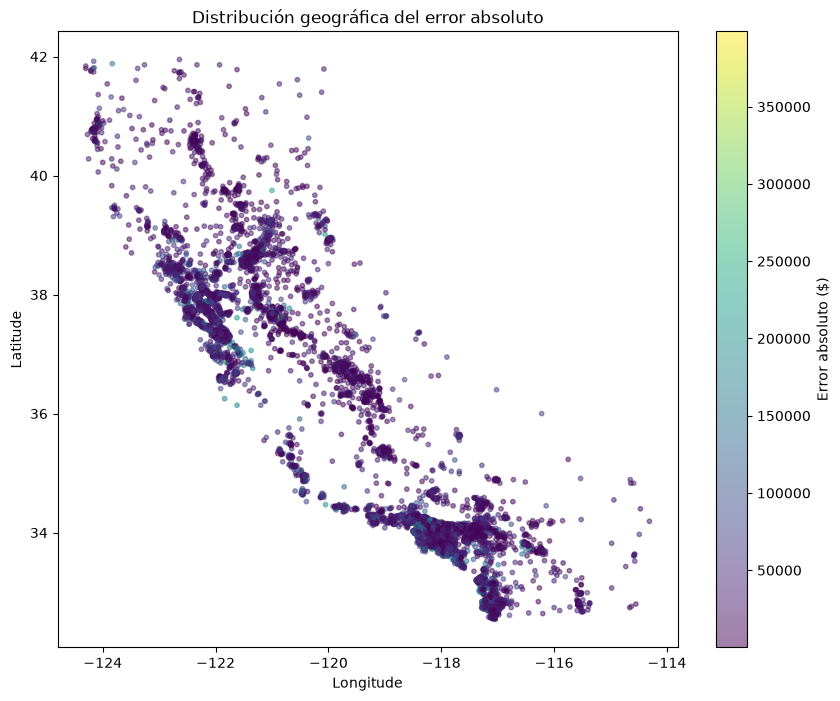

In [193]:
# Graficando un mapa de dispersion lat/long coloreado por error absoluto, para ver si el error se agrupa geograficamente
plt.figure(figsize=(10, 8))
plt.scatter(
    residuales_df_final['longitude'],
    residuales_df_final['latitude'],
    c=residuales_df_final['error_absoluto'],
    cmap='viridis',
    alpha=0.5,
    s=10
)
plt.colorbar(label='Error absoluto ($)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Distribución geográfica del error absoluto')
plt.show()

## Cierre del punto 3: análisis de residuales del modelo segmentado (interior/costa)

**Propósito:** tras validar el 28.56%/28.60% de Hipótesis 4, se analizaron los residuales del modelo segmentado por cuatro ángulos (zona, rango de precio, ingreso, lat/long), usando `residuales_df_final`, para detectar patrones que justifiquen o descarten una nueva hipótesis — en vez de probar a ciegas.

**1. Zona (`ocean_proximity`):** la segmentación cumplió su propósito específico. El error relativo de INLAND bajó de 23.66% (Fase 3, modelo único) a 20.40% (modelo segmentado) — la mejora más grande de las cuatro categorías. Las demás zonas también mejoraron, aunque menos (`<1H OCEAN` 17.09%→16.88%, `NEAR BAY` 19.95%→17.46%, `NEAR OCEAN` 19.14%→18.87%).

**2. Rango de precio:** el error absoluto sigue creciendo con el precio (mismo patrón que Fase 3), consistente con la hipótesis de que el dataset tiene un techo inherente por falta de datos a nivel de vivienda individual. Los rangos "Bajo" y "Muy Alto" mejoraron más (-16.1% y -7.8% respectivamente); "Medio" mejoró poco; "Alto" empeoró levemente ($31,241→$32,305).

**3. Ingreso (`median_income`):** el error también sube con el ingreso, pero no es una pista independiente — `median_income` y `precio_real` tienen una correlación de **0.66** (verificada con `.corr()`), así que este patrón es, en gran parte, el mismo de "rango de precio" visto desde otro ángulo.

**4. Lat/long:** el error no está uniformemente disperso en el mapa. Se observan agrupamientos de mayor error cerca de la Bahía de San Francisco (~-122, 37-38) y en una franja entre -122/-116 de longitud alrededor de 35-36 de latitud (costa central / valle central).

**Limitación persistente (no resuelta por la segmentación):** el modelo sigue produciendo predicciones negativas (mínimo -$33,835, vs. -$48,005 en Fase 3 — mejoró pero no desapareció) y predicciones muy por encima del techo de $500,000 del dataset (máximo $690,617) — comportamiento esperado de `PolynomialFeatures` + `Ridge`, que no tiene ningún límite natural en sus predicciones.

**Conclusión:** no se encontró una pista aislada y clara que justifique una hipótesis adicional obviamente ganadora — el principal patrón nuevo es el agrupamiento geográfico en la Bahía y la franja central, que podría o no ser explotable más allá de lo que ya capturan `ocean_proximity` y `distancia_ciudad`.

**Decisión final de Fase 4:** no se prueba una Hipótesis 5 de clustering geográfico. El patrón detectado en lat/long es real pero su magnitud no está clara a simple vista, y el resultado actual (28.56%/28.60%) ya está razonablemente cerca del margen de referencia (~27.8%, basado en benchmarks publicados). El costo de implementar y ajustar un clustering con KMeans (nuevo paso de fit, nueva feature, posible necesidad de reajustar ambos pipelines) no se justifica frente a una mejora incierta. Se congela el modelo segmentado (interior/costa) tal como está y se avanza a Fase 5. Este hallazgo queda anotado como candidato a explorar en una futura ronda, si se retoma el proyecto.

---
---

In [194]:
# Reentrenando pipeline_interior_new con el 100% de X_interior/y_interior (ya no solo los folds de CV); comentado tras ejecutarse una vez, para congelar el resultado
#pipeline_interior_new.fit(X_interior, y_interior)

In [195]:
# Reentrenando pipeline_costa_new con el 100% de X_costa/y_costa; comentado tras ejecutarse una vez, para congelar el resultado
#pipeline_costa_new.fit(X_costa, y_costa)

In [196]:
# Guardando ambos pipelines ya entrenados con el 100% de su segmento en artifacts/, para reusarlos en Fase 6 sin reentrenar; comentado tras ejecutarse una vez, para congelar el resultado
import joblib

#joblib.dump(pipeline_interior_new, '../artifacts/pipeline_interior_new.pkl')
#joblib.dump(pipeline_costa_new, '../artifacts/pipeline_costa_new.pkl')

## Fase 5: congelar el modelo final

**Qué se va a hacer:** terminadas las hipótesis de la Fase 4 y descartada la Hipótesis 5 (clustering geográfico), se va a reentrenar cada pipeline ganador (`pipeline_interior_new`, `pipeline_costa_new` — Ridge+Polynomial degree=2, con sus alphas óptimos de GridSearchCV) usando el **100% de `X_train_set`/`y_train_set`** de su segmento, en vez de dejarlos entrenados solo sobre los folds de validación cruzada. Esto es porque CV nunca entrena con más del 90% de los datos en cada fold — para la versión final que se va a usar sobre test, conviene aprovechar el 100% del train disponible. Ambos pipelines ya ajustados se van a guardar con `joblib` en la carpeta `artifacts/`, quedando congelados para la Fase 6.


### **Ya se entrenaron los dos modelos con el 100% de los datos, y ambos objetos pipeline han sido guardados para su posterior uso.**

In [197]:
# Cargando los dos pipelines congelados en Fase 5, ya entrenados con el 100% de train
pipeline_interior_new = joblib.load('../artifacts/pipeline_interior_new.pkl')
pipeline_costa_new = joblib.load('../artifacts/pipeline_costa_new.pkl')

In [198]:
# Cargando el test set congelado desde Fase 0, nunca antes tocado
X_test_set = pd.read_csv("../data/processed/X_test.csv")
y_test_set = pd.read_csv("../data/processed/y_test.csv")

In [199]:
# Extrayendo la columna objetivo como Series (read_csv la devuelve como DataFrame de una sola columna)
y_test_set = y_test_set["median_house_value"]

In [200]:
# Verificando la forma del test set recien cargado
X_test_set.shape

(2968, 9)

In [201]:
# Haciendo una copia explicita antes de modificar X_test_set/y_test_set, para no mutar por accidente los DataFrames originales
X_test_set, y_test_set = X_test_set.copy(), y_test_set.copy()

In [202]:
# Replicando sobre test la misma feature de dominio de Hipotesis 1: cuartos por hogar
X_test_set["rooms_per_household"] = X_test_set["total_rooms"] / X_test_set["households"]

In [203]:
# Replicando sobre test la misma feature de dominio de Hipotesis 1: proporcion de dormitorios
X_test_set["bedrooms_ratio"] = X_test_set["total_bedrooms"] / X_test_set["total_rooms"]

In [204]:
# Replicando sobre test la misma feature de dominio de Hipotesis 1: personas por hogar
X_test_set["population_per_household"] = X_test_set["population"] / X_test_set["households"]

In [205]:
# Verificando que las 3 columnas nuevas se agregaron correctamente
X_test_set.shape

(2968, 12)

In [206]:
# Replicando sobre test el mismo filtro de outliers de Hipotesis 1 (population_per_household <= 10)
def outliers_population_per_household(X, y):
    filas_validas = X['population_per_household'] <= 10
    X_filtrado = X[filas_validas]
    y_filtrado = y[filas_validas]
    return X_filtrado, y_filtrado

X_test_set, y_test_set = outliers_population_per_household(X_test_set, y_test_set)

In [207]:
# Verificando cuantas filas se eliminaron por el filtro (deberian ser pocas, igual que en train)
X_test_set.shape

(2962, 12)

In [208]:
# Replicando sobre test la misma feature de Hipotesis 2: distancia a San Francisco
X_test_set["distancia_sf"] = np.sqrt(
    (X_test_set["latitude"] - 37.7749)**2 + (X_test_set["longitude"] - (-122.4194))**2
)

In [209]:
# Replicando sobre test la misma feature de Hipotesis 2: distancia a Los Angeles
X_test_set["distancia_la"] = np.sqrt(
    (X_test_set["latitude"] - 34.0522)**2 + (X_test_set["longitude"] - (-118.2437))**2
)

In [210]:
# Replicando sobre test la misma feature de Hipotesis 2: distancia a San Diego
X_test_set["distancia_sd"] = np.sqrt(
    (X_test_set["latitude"] - 32.7157)**2 + (X_test_set["longitude"] - (-117.1611))**2
)

In [211]:
# Tomando el minimo de las 3 distancias por fila, igual que en train
X_test_set["distancia_ciudad"] = X_test_set[["distancia_sf", "distancia_la", "distancia_sd"]].min(axis=1)

In [212]:
# Eliminando las 3 columnas intermedias de distancia, igual que en train, para mantener el DataFrame limpio
X_test_set = X_test_set.drop(columns=["distancia_sf", "distancia_la", "distancia_sd"])

In [213]:
# Verificando la forma final de X_test_set, ya con todas las features replicadas
X_test_set.shape

(2962, 13)

In [214]:
# Replicando sobre test la misma mascara booleana usada en train para separar interior de costa
es_interior_x_test = X_test_set['ocean_proximity'] == 'INLAND'

X_test_interior = X_test_set[es_interior_x_test]
y_test_interior = y_test_set[es_interior_x_test]

In [215]:
# Verificando cuantas filas de test quedaron en el segmento interior
print(X_test_interior.shape)
print(y_test_interior.shape)

(1028, 13)
(1028,)


In [216]:
# Invirtiendo la mascara para obtener el segmento de costa de test
es_costa_x_test = ~es_interior_x_test
X_test_costa = X_test_set[es_costa_x_test]
y_test_costa = y_test_set[es_costa_x_test]

In [217]:
# Verificando cuantas filas de test quedaron en el segmento costa
print(X_test_costa.shape)
print(y_test_costa.shape)

(1934, 13)
(1934,)


In [218]:
# Prediciendo cada segmento de test con su pipeline ya entrenado (sin reentrenar ni reajustar nada)
predicciones_test_interior = pipeline_interior_new.predict(X_test_interior)
predicciones_test_costa = pipeline_costa_new.predict(X_test_costa)

In [219]:
# Uniendo las predicciones y los valores reales de ambos segmentos de test en un solo conjunto
predicciones_test_final = np.concatenate([predicciones_test_interior, predicciones_test_costa])
reales_test_final = np.concatenate([y_test_interior, y_test_costa])

In [220]:
# Calculando el RMSE real final sobre el test set combinado, y convirtiendolo a porcentaje sobre la mediana de train
rmse_test_final = root_mean_squared_error(reales_test_final, predicciones_test_final)
porcentaje_test_final = rmse_test_final / precio_mediana_rid_poly_3 * 100
print(porcentaje_test_final)

28.68416501777738


## Fase 6: evaluación final sobre el test de la Ronda 2

**Qué se va a hacer:** se va a cargar el modelo congelado en la Fase 5 (`pipeline_interior_new`, `pipeline_costa_new`, leídos desde `artifacts/` con `joblib`) y evaluarlo contra `X_test.csv`/`y_test.csv` — el test set de la Ronda 2, separado desde la Fase 0 y nunca tocado hasta ahora. Se le van a replicar a test exactamente las mismas transformaciones manuales hechas en train durante la Fase 4 (features de dominio, filtro de outliers, `distancia_ciudad`), se van a segmentar sus filas con la misma máscara `ocean_proximity == 'INLAND'`, predecir cada segmento con el pipeline ya entrenado (sin reentrenar nada), y calcular un único RMSE real combinando ambos segmentos. Esta es la **única vez** que se toca el test set, siguiendo la regla de no contaminar la medida de generalización.


## Cierre de Fase 6: evaluación final sobre el test de la Ronda 2

**Propósito:** evaluar el modelo final congelado (interior/costa, Fase 5) contra el test set de la Ronda 2 — intacto y nunca antes usado — para obtener una medida honesta de generalización. Esta evaluación se hace **una sola vez**, según la regla del proyecto.

**Construcción:**
- Se cargó `X_test.csv`/`y_test.csv` (el split congelado en Fase 0, `random_state=52`).
- Se replicaron sobre `X_test_set` las mismas transformaciones manuales hechas en train durante Fase 4: `rooms_per_household`, `bedrooms_ratio`, `population_per_household` (+ filtro `population_per_household <= 10`, que eliminó 6 de 2,968 filas) y `distancia_ciudad` (mínimo de las distancias a SF/LA/San Diego).
- Se dividió `X_test_set` con la misma máscara `ocean_proximity == 'INLAND'` usada en train (1,028 filas interior, 1,934 costa).
- Se usaron los pipelines ya entrenados con el 100% de train (`pipeline_interior_new`, `pipeline_costa_new`, cargados desde `artifacts/`) para predecir cada segmento — sin reentrenar ni volver a ajustar nada.
- Se combinaron las predicciones y los valores reales de ambos segmentos, y se calculó un único RMSE real con `root_mean_squared_error`.

**Resultado:**

| Etapa | % sobre mediana de train |
|---|---|
| Línea base (Fase 2, sin features nuevas) | 30.26% |
| Hipótesis 4 (segmentado, combinación matemática) | 28.56% |
| Validación con `cross_val_predict` (train, out-of-sample) | 28.60% |
| **Test final (Ronda 2, nunca antes visto)** | **28.68%** |

**Conclusión:** el resultado en test (28.68%) está a solo 0.08 puntos porcentuales de la validación en train (28.60%) — una diferencia mínima que confirma que el modelo **generaliza bien** y no estaba sobreajustado a train, a pesar de las múltiples hipótesis probadas y ajustes hechos sobre ese mismo conjunto. El resultado también queda razonablemente cerca del margen de referencia externo (~27.8%, benchmark de RandomForest publicado para este dataset). El test de la Ronda 2 queda **consumido** — no se vuelve a tocar; cualquier iteración futura requeriría un split nuevo.